# Charging Demand Intensity per NUTS-2 Region\n\nPrimary metric: **MWh per highway-km** — how much charging infrastructure density\nis needed per unit of highway. Secondary metric: kWh/km\u00b2 (spatial density).\n\nUsed for manuscript sections 4.2 (corridor-wide) and 4.5 (DE-AT-IT border).

In [190]:
import yaml
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib import cm
from pathlib import Path
from collections import defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
})

BASE_PATH = Path.cwd()
INPUT_DIR = BASE_PATH / 'input_data'
RESULTS_DIR = BASE_PATH / 'results'
FIG_DIR = BASE_PATH / 'figures'
FIG_DIR.mkdir(exist_ok=True)
print(f'Base path: {BASE_PATH}')

Base path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM


In [191]:
# ============================================================
# Scenario configuration — matching visualize_4_scenarios.ipynb
# NOTE: Go RES now points to scenario_000 (new run 2026-02-11)
# ============================================================
SCENARIOS = {
    'scenario_000': {'name': 'Go RES',         'color': '#335c67'},
    'scenario_001': {'name': 'NECPEssentials',  'color': '#e09f3e'},
    'scenario_002': {'name': 'REPowerEU++',     'color': '#457b9d'},
    'scenario_003': {'name': 'Trinity',         'color': '#9e2a2b'},
}

# Derived helpers for downstream cells (keyed by display name)
SCEN_NAMES = [cfg['name'] for cfg in SCENARIOS.values()]
SCENARIO_COLORS = {cfg['name']: cfg['color'] for cfg in SCENARIOS.values()}

CORRIDOR_COUNTRIES = ['AT', 'DE', 'IT', 'DK', 'SE', 'NO', 'FI']

# Border regions (DE-AT-IT)
SOUTHERN_BORDER_REGIONS = {
    'AT33', 'AT34',                    # Austria — Tyrol, Vorarlberg
    'ITC4', 'ITH1', 'ITH2', 'ITH3',   # Italy — Lombardy, Trentino, Friuli, Veneto
    'DE14', 'DE21', 'DE27',            # Germany — Tuebingen, Oberbayern, Schwaben
}

REGION_NAMES = {
    'AT33': 'Tyrol', 'AT34': 'Vorarlberg',
    'ITC4': 'Lombardy', 'ITH1': 'Trentino-Alto Adige',
    'ITH2': 'Friuli-Venezia Giulia', 'ITH3': 'Veneto',
    'DE14': 'Tuebingen', 'DE21': 'Upper Bavaria', 'DE27': 'Swabia',
}

COUNTRY_COLORS_MAP = {
    'AT': '#E74C3C', 'IT': '#27AE60', 'DE': '#3498DB',
    'DK': '#e15759', 'SE': '#f28e2c', 'NO': '#4e79a7', 'FI': '#76b7b2',
}

MODEL_YEARS = list(range(2020, 2061, 4))
ANALYSIS_YEARS = [2032, 2040, 2048]
Y_INIT = 2020
TIME_STEP = 4

print(f'Scenarios: {SCEN_NAMES}')
print(f'Analysis years: {ANALYSIS_YEARS}')


Scenarios: ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']
Analysis years: [2032, 2040, 2048]


In [192]:
# ============================================================
# Data loading utilities
# ============================================================

def load_yaml_file(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f)

def load_yaml_file_numpy(filepath):
    """Use UnsafeLoader for files containing numpy scalar tags."""
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.load(f, Loader=yaml.UnsafeLoader)

def find_latest_result_file(scenario_folder, variable):
    """Find the latest result file for a given variable (by modification time)."""
    pattern = f"*_{variable}_dict.yaml"
    files = list(scenario_folder.glob(pattern))
    if not files:
        return None
    return max(files, key=lambda x: x.stat().st_mtime)

_CI_RE = re.compile(r'CartesianIndex\(([^)]+)\)')

def parse_ci(key_str):
    """Parse CartesianIndex(a, b, ...) -> tuple of ints."""
    m = _CI_RE.search(str(key_str))
    if m:
        return tuple(int(x.strip()) for x in m.group(1).split(','))
    return None

def parse_tuple_key(key_str):
    """Parse tuple-format key string -> tuple of ints."""
    nums = re.findall(r'-?\d+', str(key_str))
    return tuple(int(x) for x in nums)

def load_f_dict(filepath):
    """Load f_dict and parse keys to structured format.
    f_dict key: (year, (product, odpair, path), (mode, tv), generation)
    Returns: dict with parsed tuple keys -> float values
    """
    raw = load_yaml_file(filepath)
    result = {}
    for k, v in raw.items():
        nums = parse_tuple_key(k)
        if len(nums) >= 7:
            year = nums[0]
            product, odpair, path_id = nums[1], nums[2], nums[3]
            mode_id, tv_id = nums[4], nums[5]
            gen = nums[6]
            key = (year, (product, odpair, path_id), (mode_id, tv_id), gen)
            result[key] = float(v)
    return result

def load_geo_elements(input_dir):
    """Load geographic elements and build lookup by ID."""
    geo_yaml = load_yaml_file(input_dir / 'GeographicElement.yaml')
    geo_by_id = {}
    for g in geo_yaml:
        if g.get('type') == 'node':
            geo_by_id[g['id']] = {
                'name': g.get('name', ''),
                'nuts2_region': g.get('nuts2_region', ''),
                'country': g.get('country', ''),
                'coordinate_lat': g.get('coordinate_lat', 0),
                'coordinate_long': g.get('coordinate_long', 0),
            }
    return geo_by_id

def load_paths(input_dir):
    """Load path data — use fixed_nuts_2 for complete path set."""
    path_file = input_dir.parent.parent / 'fixed_nuts_2' / 'Path.yaml'
    if not path_file.exists():
        path_file = input_dir / 'Path.yaml'
    path_yaml = load_yaml_file_numpy(path_file)
    path_by_id = {}
    for p in path_yaml:
        path_by_id[p['id']] = {
            'sequence': [int(x) for x in p.get('sequence', [])],
            'distance_from_previous': [float(x) for x in p.get('distance_from_previous', [])],
        }
    return path_by_id

def load_tech_vehicles(input_dir):
    """Load TechVehicle parameters."""
    tv_yaml = load_yaml_file(input_dir / 'TechVehicle.yaml')
    spec_cons = {}  # kWh/km by tv_id, list by annual year
    w_payload = {}  # tonnes payload
    for tv in tv_yaml:
        spec_cons[tv['id']] = tv['spec_cons']
        w_payload[tv['id']] = tv['W']
    return spec_cons, w_payload

print('Loading functions defined.')


Loading functions defined.


In [193]:
# ============================================================
# Load all scenario data
# ============================================================
data = {}

for scen_id, cfg in SCENARIOS.items():
    scen_name = cfg['name']
    print(f'\nLoading {scen_name} ({scen_id})...')

    scen_dir = RESULTS_DIR / 'uncertainty_scenarios' / scen_id
    input_dir = INPUT_DIR / 'uncertainty_scenarios' / scen_id

    # Load f_dict (latest run)
    f_file = find_latest_result_file(scen_dir, 'f')
    if f_file is None:
        print(f'  WARNING: No f_dict found in {scen_dir}')
        continue
    print(f'  f_dict: {f_file.name}')
    f_dict = load_f_dict(f_file)
    print(f'  f_dict: {len(f_dict)} entries')

    # Load geographic elements
    geo_by_id = load_geo_elements(input_dir)
    print(f'  geo elements: {len(geo_by_id)} nodes')

    # Load paths (from fixed_nuts_2 for complete set)
    path_by_id = load_paths(input_dir)
    print(f'  paths: {len(path_by_id)}')

    # Load tech vehicle params
    spec_cons, w_payload = load_tech_vehicles(input_dir)

    data[scen_name] = {
        'f': f_dict,
        'geo_by_id': geo_by_id,
        'path_by_id': path_by_id,
        'spec_cons': spec_cons,
        'w_payload': w_payload,
    }

print(f'\nLoaded {len(data)} scenarios.')



Loading Go RES (scenario_000)...
  f_dict: scenario_000_cs_2026-02-11_11-52-48_f_dict.yaml
  f_dict: 166056 entries
  geo elements: 81 nodes
  paths: 6055

Loading NECPEssentials (scenario_001)...
  f_dict: scenario_001_cs_2026-02-11_12-14-54_f_dict.yaml
  f_dict: 166056 entries
  geo elements: 81 nodes
  paths: 6055

Loading REPowerEU++ (scenario_002)...
  f_dict: scenario_002_cs_2026-02-11_12-48-36_f_dict.yaml
  f_dict: 166056 entries
  geo elements: 81 nodes
  paths: 6055

Loading Trinity (scenario_003)...
  f_dict: scenario_003_cs_2026-02-11_13-15-34_f_dict.yaml
  f_dict: 166056 entries
  geo elements: 81 nodes
  paths: 6055

Loaded 4 scenarios.


In [194]:
# ============================================================
# Load NUTS-2 shapefile, areas, and highway-km data
# ============================================================
nuts_shp_path = BASE_PATH / 'data' / 'NUTS_RG_20M_2021_4326.shp' / 'NUTS_RG_20M_2021_4326.shp'
nuts_gdf = gpd.read_file(nuts_shp_path)
print(f'Loaded {len(nuts_gdf)} NUTS regions')

# Filter NUTS-2 level
nuts2_gdf = nuts_gdf[nuts_gdf['LEVL_CODE'] == 2].copy()

# Reproject to ETRS89-LAEA for accurate area in km²
nuts2_proj = nuts2_gdf.to_crs('EPSG:3035')
nuts2_proj['area_km2'] = nuts2_proj.geometry.area / 1e6

# Transfer area back to WGS84 frame
nuts2_gdf = nuts2_gdf.merge(
    nuts2_proj[['NUTS_ID', 'area_km2']].drop_duplicates('NUTS_ID'),
    on='NUTS_ID', how='left'
)

# Filter corridor countries
corridor_nuts2 = nuts2_gdf[nuts2_gdf['CNTR_CODE'].isin(CORRIDOR_COUNTRIES)].copy()
print(f'Corridor NUTS-2 regions: {len(corridor_nuts2)}')

# Area lookup
area_by_nuts2 = dict(zip(corridor_nuts2['NUTS_ID'], corridor_nuts2['area_km2']))

# Load highway-km per NUTS-2
highway_df = pd.read_csv(BASE_PATH / 'highway_km_per_nuts2.csv')
highway_by_nuts2 = dict(zip(highway_df['NUTS2_CODE'], highway_df['highway_km']))
corridor_hw = {k: v for k, v in highway_by_nuts2.items()
               if k[:2] in CORRIDOR_COUNTRIES and v > 0}
print(f'Highway data: {len(corridor_hw)} corridor regions with >0 km')

# Show border region highway-km
print('\nBorder region highway-km:')
for r in sorted(SOUTHERN_BORDER_REGIONS):
    hw = highway_by_nuts2.get(r, 0)
    area = area_by_nuts2.get(r, 0)
    print(f'  {r} ({REGION_NAMES.get(r, "")}): {hw:.1f} highway-km, {area:,.0f} km²')

# Country boundaries for map context
nuts0 = nuts_gdf[nuts_gdf['LEVL_CODE'] == 0].copy()
corridor_countries_gdf = nuts0[nuts0['CNTR_CODE'].isin(CORRIDOR_COUNTRIES)]

# Build geo_id -> nuts2 mapping (same across all scenarios)
ref_geo = data['Go RES']['geo_by_id']
geo_to_nuts2 = {gid: g['nuts2_region'] for gid, g in ref_geo.items()}

Loaded 2010 NUTS regions
Corridor NUTS-2 regions: 93
Highway data: 89 corridor regions with >0 km

Border region highway-km:
  AT33 (Tyrol): 189.0 highway-km, 12,620 km²
  AT34 (Vorarlberg): 63.0 highway-km, 2,602 km²
  DE14 (Tuebingen): 274.4 highway-km, 9,359 km²
  DE21 (Upper Bavaria): 633.9 highway-km, 17,457 km²
  DE27 (Swabia): 364.5 highway-km, 10,038 km²
  ITC4 (Lombardy): 740.0 highway-km, 23,897 km²
  ITH1 (Trentino-Alto Adige): 187.0 highway-km, 7,440 km²
  ITH2 (Friuli-Venezia Giulia): 0.0 highway-km, 6,272 km²
  ITH3 (Veneto): 701.0 highway-km, 18,211 km²


In [195]:
# ============================================================
# Compute BEV electricity consumption per NUTS-2 region
# Walks f_dict flows along path sequences to estimate energy
# ============================================================

def energy_by_nuts2(f_dict, path_by_id, geo_by_id, spec_cons, w_payload,
                    target_year, tv_filter=1):
    """
    Estimate BEV electricity consumption per NUTS-2 region.
    
    For each BEV flow: energy = (ktonnes * 1000 / W) * spec_cons * segment_km
    Returns: {nuts2_code: total_mwh}
    """
    result = defaultdict(float)
    
    for key, tonnes_kt in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        path_id = key[1][2]
        mode_id = key[2][0]
        tv_id = key[2][1]
        gen = key[3]
        
        if mode_id != 1:   # road only
            continue
        if tv_id != tv_filter:  # BEV only
            continue
        if tonnes_kt <= 0:
            continue
        
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        
        gen_idx = min(max(gen - Y_INIT, 0), len(spec_cons[tv_id]) - 1)
        sc = spec_cons[tv_id][gen_idx]     # kWh/km
        w = w_payload[tv_id][gen_idx]       # tonnes
        
        sequence = path_info['sequence']
        dist_from_prev = path_info['distance_from_previous']
        
        for i, node_id in enumerate(sequence):
            geo = geo_by_id.get(node_id)
            if geo is None:
                continue
            
            segment_km = dist_from_prev[i]
            if segment_km <= 0:
                continue
            
            nuts2 = geo.get('nuts2_region', '')
            if not nuts2:
                continue
            
            # Energy = (ktonnes * 1000 / W) * spec_cons * segment_km / 1000 -> MWh
            energy_mwh = (tonnes_kt * 1000 / w) * sc * segment_km / 1000
            result[nuts2] += energy_mwh
    
    return dict(result)

# Compute for all scenarios and analysis years
energy_nuts2 = {}  # {scen: {year: {nuts2_code: mwh}}}

for scen_name, d in data.items():
    energy_nuts2[scen_name] = {}
    for year in ANALYSIS_YEARS:
        energy_nuts2[scen_name][year] = energy_by_nuts2(
            d['f'], d['path_by_id'], d['geo_by_id'],
            d['spec_cons'], d['w_payload'], year
        )
        total = sum(energy_nuts2[scen_name][year].values())
        n = len(energy_nuts2[scen_name][year])
        print(f'  {scen_name} {year}: {n} NUTS-2 regions, {total/1e3:,.0f} GWh')

print('\nEnergy computation done.')

  Go RES 2032: 81 NUTS-2 regions, 403 GWh
  Go RES 2040: 81 NUTS-2 regions, 1,695 GWh
  Go RES 2048: 81 NUTS-2 regions, 2,221 GWh
  NECPEssentials 2032: 81 NUTS-2 regions, 491 GWh
  NECPEssentials 2040: 81 NUTS-2 regions, 1,352 GWh
  NECPEssentials 2048: 81 NUTS-2 regions, 1,907 GWh
  REPowerEU++ 2032: 81 NUTS-2 regions, 925 GWh
  REPowerEU++ 2040: 81 NUTS-2 regions, 1,730 GWh
  REPowerEU++ 2048: 81 NUTS-2 regions, 2,242 GWh
  Trinity 2032: 81 NUTS-2 regions, 512 GWh
  Trinity 2040: 81 NUTS-2 regions, 1,354 GWh
  Trinity 2048: 81 NUTS-2 regions, 1,897 GWh

Energy computation done.


In [196]:
# ============================================================
# Build intensity table: MWh/highway-km and kWh/km² per NUTS-2
# ============================================================

def build_intensity_df(energy_nuts2, area_by_nuts2, highway_by_nuts2, ref_geo, year):
    """Build DataFrame with MWh/highway-km and kWh/km² for all scenarios."""
    rows = []
    all_nuts2 = set()
    for scen_name in energy_nuts2:
        all_nuts2 |= set(energy_nuts2[scen_name][year].keys())
    
    nuts2_country = {}
    for gid, g in ref_geo.items():
        n2 = g.get('nuts2_region', '')
        if n2:
            nuts2_country[n2] = g.get('country', n2[:2])
    
    for nuts2 in sorted(all_nuts2):
        area = area_by_nuts2.get(nuts2, 0)
        hw_km = highway_by_nuts2.get(nuts2, 0)
        country = nuts2_country.get(nuts2, nuts2[:2])
        row = {
            'nuts2': nuts2,
            'country': country,
            'area_km2': area,
            'highway_km': hw_km,
            'is_border': nuts2 in SOUTHERN_BORDER_REGIONS,
        }
        for scen_name in energy_nuts2:
            mwh = energy_nuts2[scen_name][year].get(nuts2, 0)
            row[f'{scen_name}_mwh'] = mwh
            row[f'{scen_name}_kwh_per_km2'] = (mwh * 1000) / area if area > 0 else 0
            row[f'{scen_name}_mwh_per_hwkm'] = mwh / hw_km if hw_km > 0 else 0
        rows.append(row)
    
    return pd.DataFrame(rows)

# Build for each analysis year
intensity_dfs = {}
for year in ANALYSIS_YEARS:
    intensity_dfs[year] = build_intensity_df(
        energy_nuts2, area_by_nuts2, highway_by_nuts2, ref_geo, year
    )
    df = intensity_dfs[year]
    valid = df[df['highway_km'] > 0]
    mean_hw = valid['Go RES_mwh_per_hwkm'].mean()
    max_hw = valid['Go RES_mwh_per_hwkm'].max()
    max_nuts2 = valid.loc[valid['Go RES_mwh_per_hwkm'].idxmax(), 'nuts2']
    print(f'{year}: {len(valid)} regions with highway, '
          f'mean={mean_hw:,.0f} MWh/highway-km, '
          f'max={max_hw:,.0f} MWh/highway-km ({max_nuts2})')

# Show top-10 for 2040
print('\n--- Top 10 NUTS-2 regions by MWh/highway-km (Go RES, 2040) ---')
valid = intensity_dfs[2040][intensity_dfs[2040]['highway_km'] > 0]
top10 = valid.nlargest(10, 'Go RES_mwh_per_hwkm')
for _, r in top10.iterrows():
    border = ' [BORDER]' if r['is_border'] else ''
    print(f"  {r['nuts2']} ({r['country']}): {r['Go RES_mwh_per_hwkm']:>8,.0f} MWh/hw-km "
          f"({r['Go RES_mwh']/1e3:.1f} GWh, {r['highway_km']:.0f} hw-km){border}")

2032: 79 regions with highway, mean=32 MWh/highway-km, max=951 MWh/highway-km (SE33)
2040: 79 regions with highway, mean=138 MWh/highway-km, max=3,867 MWh/highway-km (SE33)
2048: 79 regions with highway, mean=177 MWh/highway-km, max=4,660 MWh/highway-km (SE33)

--- Top 10 NUTS-2 regions by MWh/highway-km (Go RES, 2040) ---
  SE33 (SE):    3,867 MWh/hw-km (23.2 GWh, 6 hw-km)
  SE32 (SE):    1,056 MWh/hw-km (30.6 GWh, 29 hw-km)
  SE31 (SE):      793 MWh/hw-km (49.2 GWh, 62 hw-km)
  NO06 (NO):      431 MWh/hw-km (12.1 GWh, 28 hw-km)
  DE25 (DE):      292 MWh/hw-km (78.1 GWh, 268 hw-km)
  AT33 (AT):      263 MWh/hw-km (49.6 GWh, 189 hw-km) [BORDER]
  DE26 (DE):      233 MWh/hw-km (71.1 GWh, 305 hw-km)
  SE22 (SE):      224 MWh/hw-km (88.7 GWh, 395 hw-km)
  DE91 (DE):      197 MWh/hw-km (48.6 GWh, 247 hw-km)
  DE24 (DE):      183 MWh/hw-km (47.9 GWh, 262 hw-km)


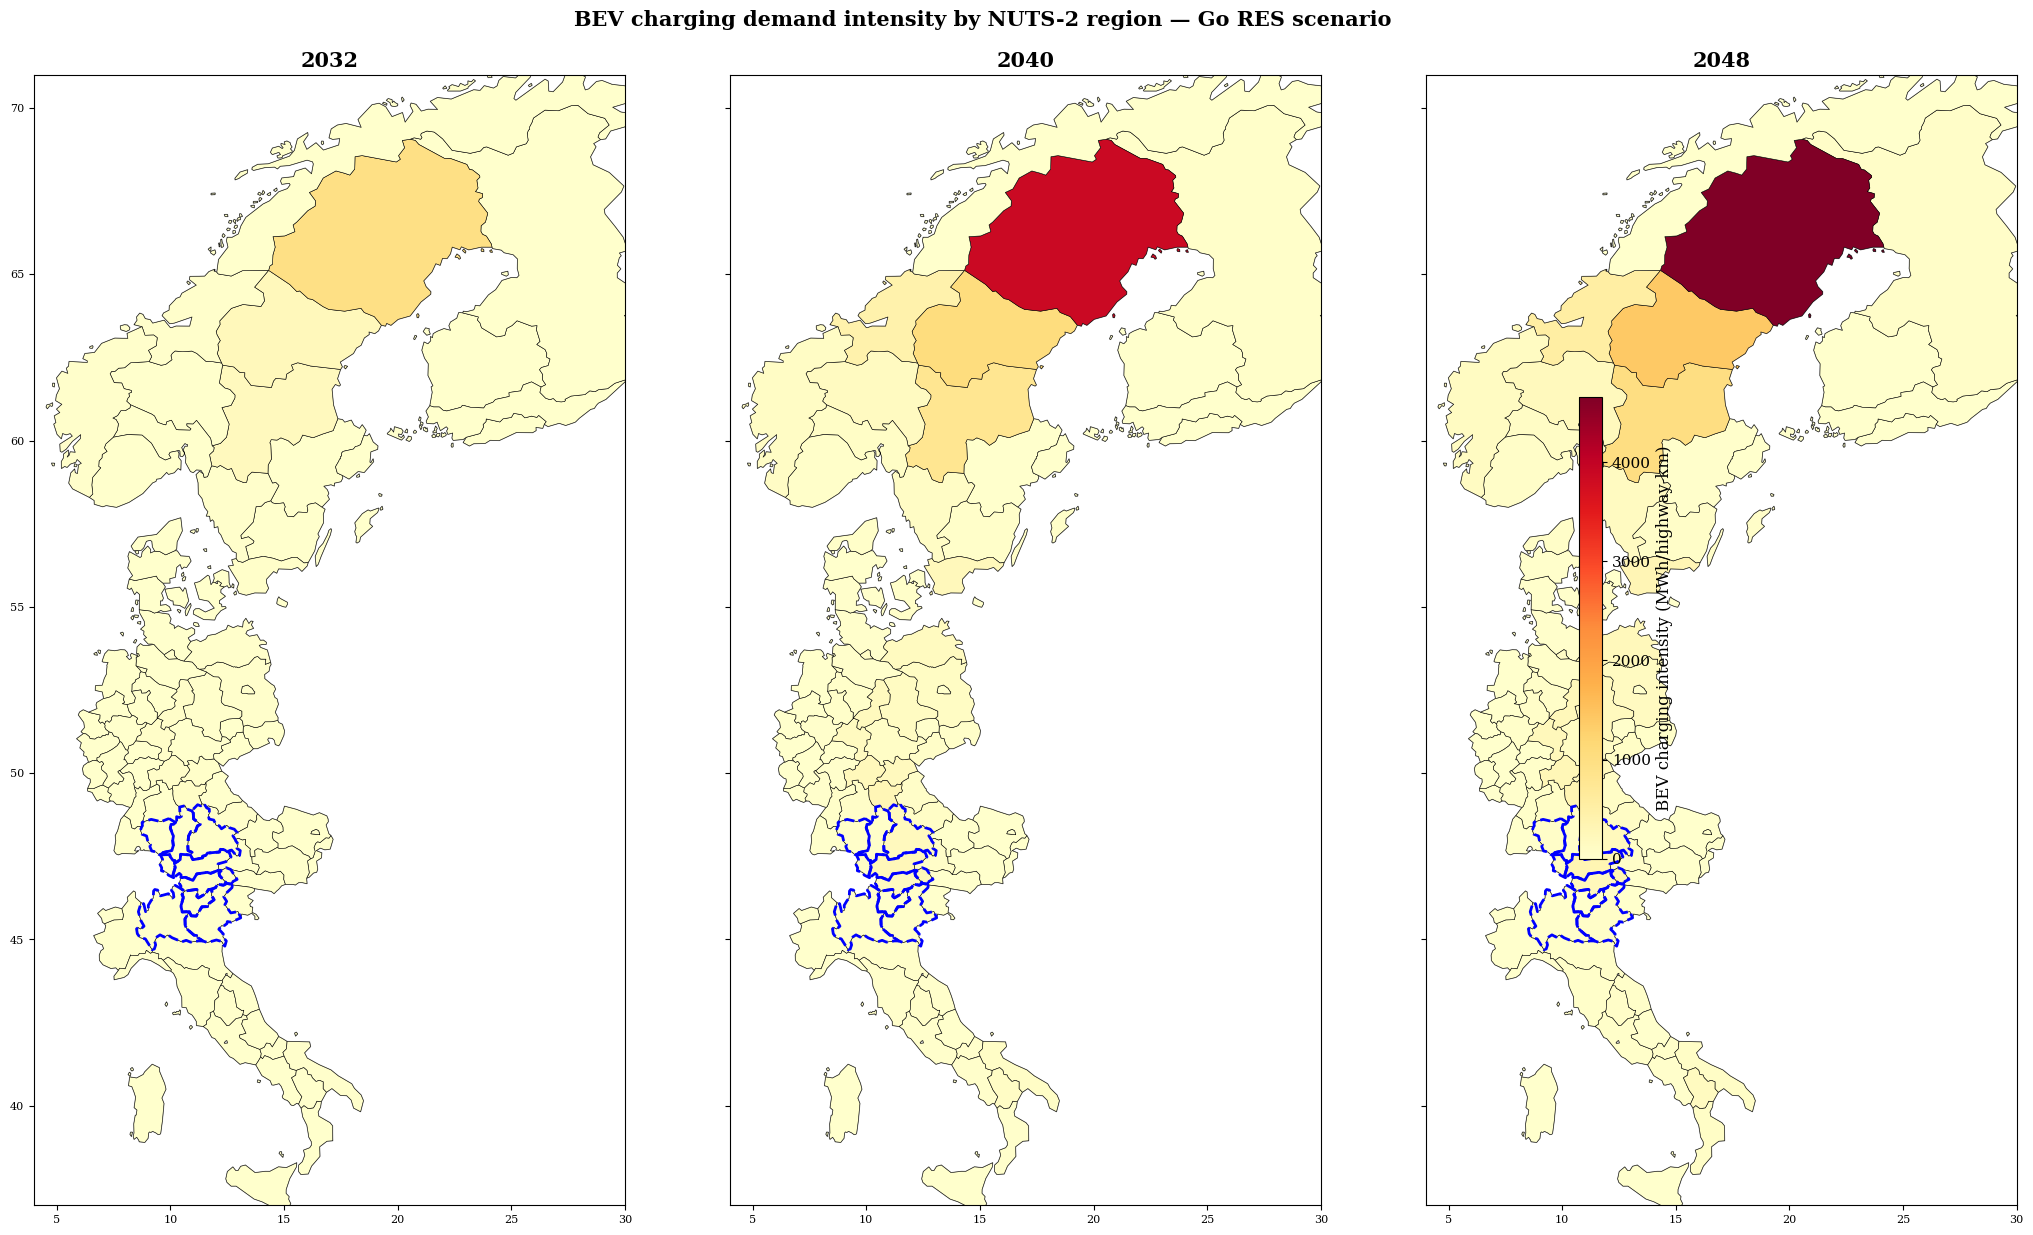

Saved: figures/charging_intensity_corridor_GoRES.pdf


In [197]:
# ============================================================
# Figure 1: Choropleth map — MWh/highway-km across full corridor
# One panel per analysis year, Go RES scenario
# ============================================================

fig, axes = plt.subplots(1, len(ANALYSIS_YEARS), figsize=(7 * len(ANALYSIS_YEARS), 12))

# Merge highway data into corridor gdf
corridor_with_hw = corridor_nuts2.merge(
    highway_df.rename(columns={'NUTS2_CODE': 'NUTS_ID'}),
    on='NUTS_ID', how='left'
)

vmax = 0
for year in ANALYSIS_YEARS:
    df = intensity_dfs[year]
    valid = df[df['highway_km'] > 0]
    vmax = max(vmax, valid['Go RES_mwh_per_hwkm'].max())

for yi, year in enumerate(ANALYSIS_YEARS):
    ax = axes[yi]
    df = intensity_dfs[year]
    
    plot_gdf = corridor_with_hw.merge(
        df[['nuts2', 'Go RES_mwh_per_hwkm']],
        left_on='NUTS_ID', right_on='nuts2', how='left'
    )
    plot_gdf['Go RES_mwh_per_hwkm'] = plot_gdf['Go RES_mwh_per_hwkm'].fillna(0)
    
    corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
    
    plot_gdf.plot(
        ax=ax, column='Go RES_mwh_per_hwkm',
        cmap='YlOrRd', edgecolor='black', linewidth=0.4,
        vmin=0, vmax=vmax, legend=False,
    )
    
    border_gdf = plot_gdf[plot_gdf['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)]
    border_gdf.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=2, linestyle='--')
    
    ax.set_xlim(4, 30)
    ax.set_ylim(37, 71)
    ax.set_title(f'{year}', fontweight='bold', fontsize=15)
    if yi > 0:
        ax.set_yticklabels([])
    ax.tick_params(labelsize=8)

sm = cm.ScalarMappable(cmap='YlOrRd', norm=Normalize(vmin=0, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), shrink=0.5, pad=0.02)
cbar.set_label('BEV charging intensity (MWh/highway-km)', fontsize=12)

fig.suptitle('BEV charging demand intensity by NUTS-2 region \u2014 Go RES scenario',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'charging_intensity_corridor_GoRES.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'charging_intensity_corridor_GoRES.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/charging_intensity_corridor_GoRES.pdf')

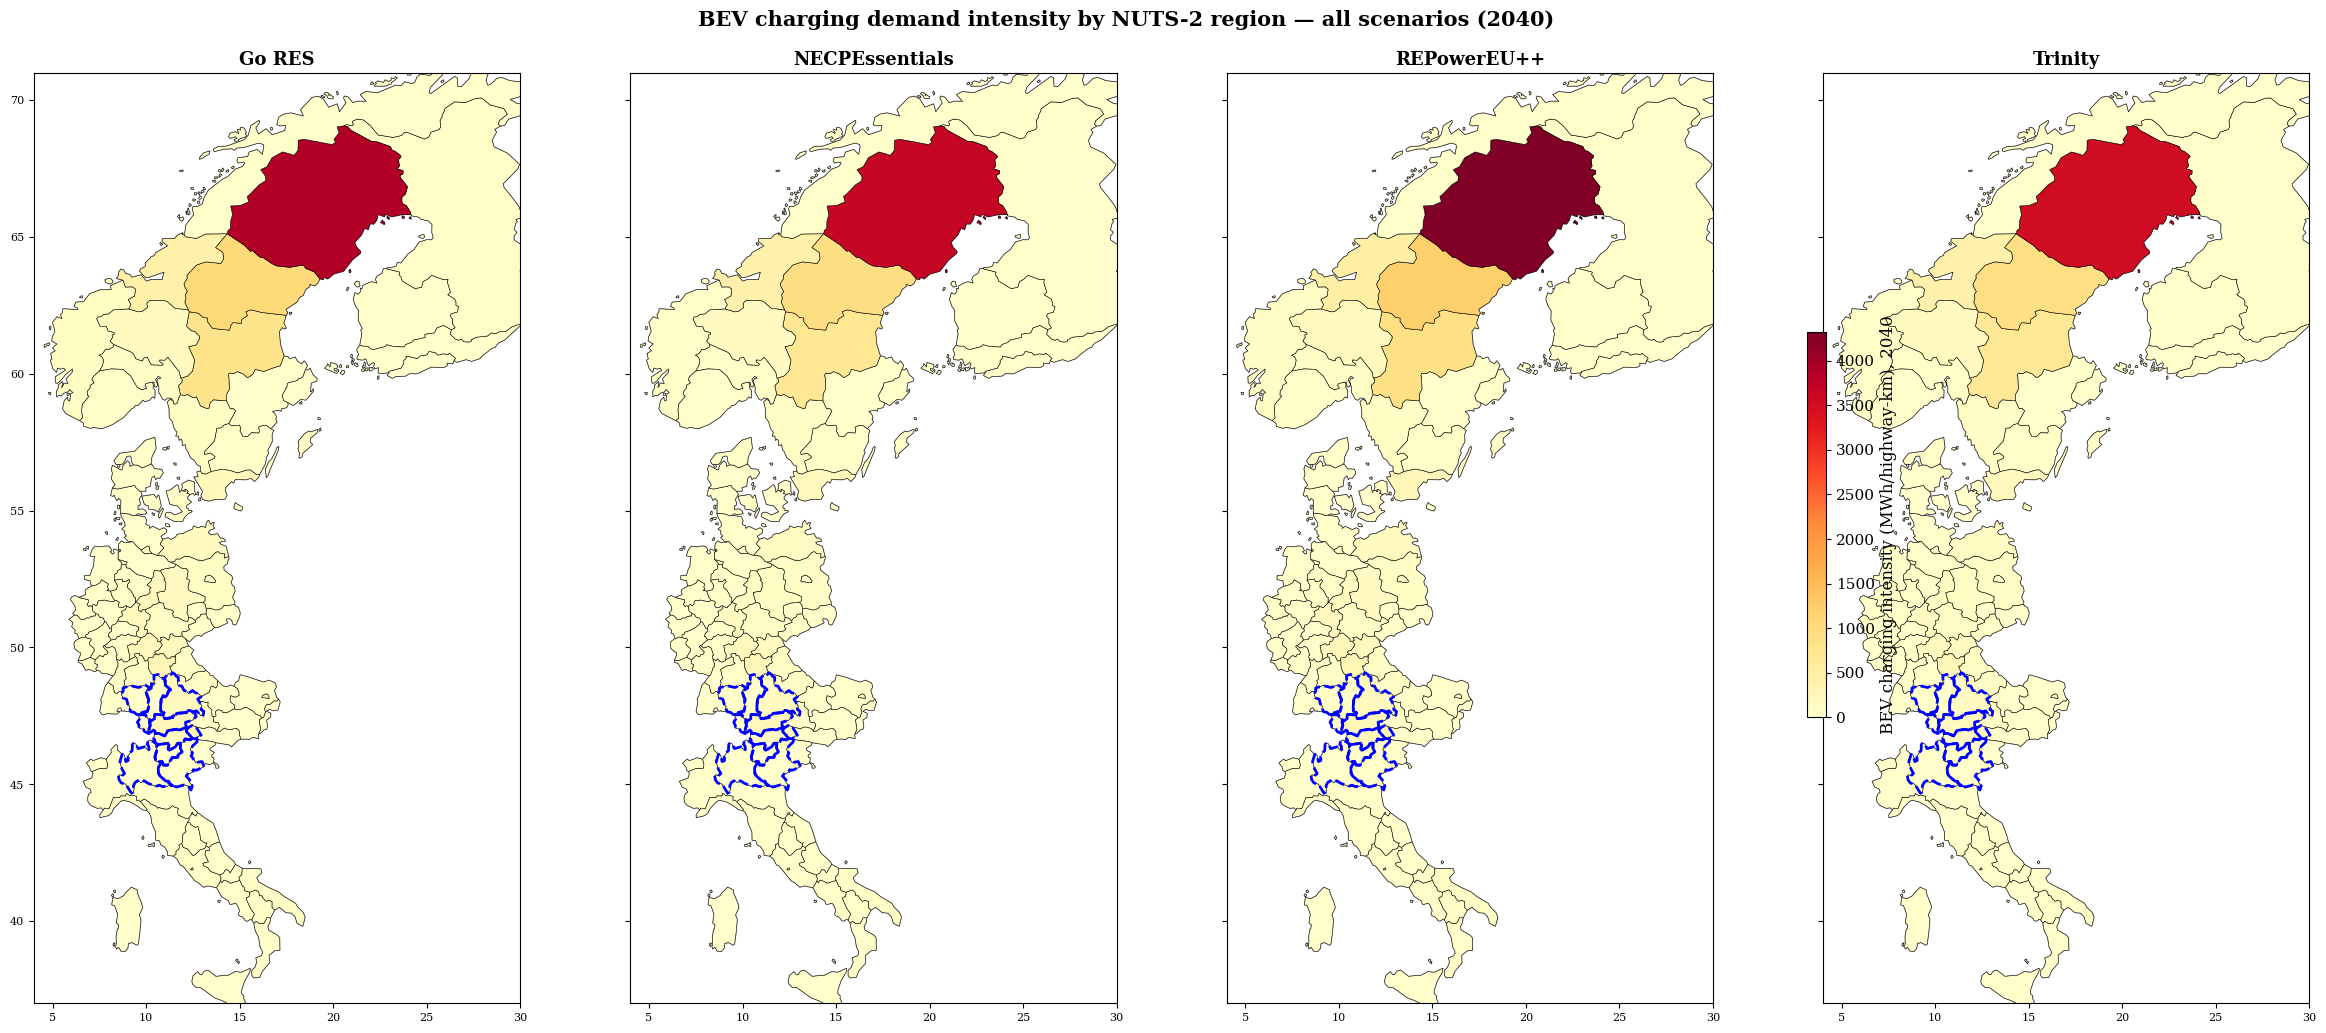

Saved: figures/charging_intensity_hwkm_4scenarios_2040.pdf


In [198]:
# ============================================================
# Figure 2: Choropleth — MWh/highway-km, 4 scenarios x 2040
# ============================================================

PLOT_YEAR = 2040
scen_names = SCEN_NAMES
fig, axes = plt.subplots(1, 4, figsize=(24, 10))

vmax = max(
    intensity_dfs[PLOT_YEAR][intensity_dfs[PLOT_YEAR]['highway_km'] > 0][f'{s}_mwh_per_hwkm'].max()
    for s in scen_names
)

for si, scen_name in enumerate(scen_names):
    ax = axes[si]
    df = intensity_dfs[PLOT_YEAR]
    col = f'{scen_name}_mwh_per_hwkm'
    
    plot_gdf = corridor_with_hw.merge(
        df[['nuts2', col]], left_on='NUTS_ID', right_on='nuts2', how='left'
    )
    plot_gdf[col] = plot_gdf[col].fillna(0)
    
    corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
    plot_gdf.plot(
        ax=ax, column=col, cmap='YlOrRd',
        edgecolor='black', linewidth=0.4,
        vmin=0, vmax=vmax, legend=False,
    )
    
    border_gdf = plot_gdf[plot_gdf['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)]
    border_gdf.plot(ax=ax, facecolor='none', edgecolor='blue', linewidth=2, linestyle='--')
    
    ax.set_xlim(4, 30)
    ax.set_ylim(37, 71)
    ax.set_title(scen_name, fontweight='bold', fontsize=13)
    if si > 0:
        ax.set_yticklabels([])
    ax.tick_params(labelsize=8)

sm = cm.ScalarMappable(cmap='YlOrRd', norm=Normalize(vmin=0, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), shrink=0.5, pad=0.02)
cbar.set_label(f'BEV charging intensity (MWh/highway-km), {PLOT_YEAR}', fontsize=12)

fig.suptitle(f'BEV charging demand intensity by NUTS-2 region \u2014 all scenarios ({PLOT_YEAR})',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_4scenarios_{PLOT_YEAR}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_4scenarios_{PLOT_YEAR}.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: figures/charging_intensity_hwkm_4scenarios_{PLOT_YEAR}.pdf')

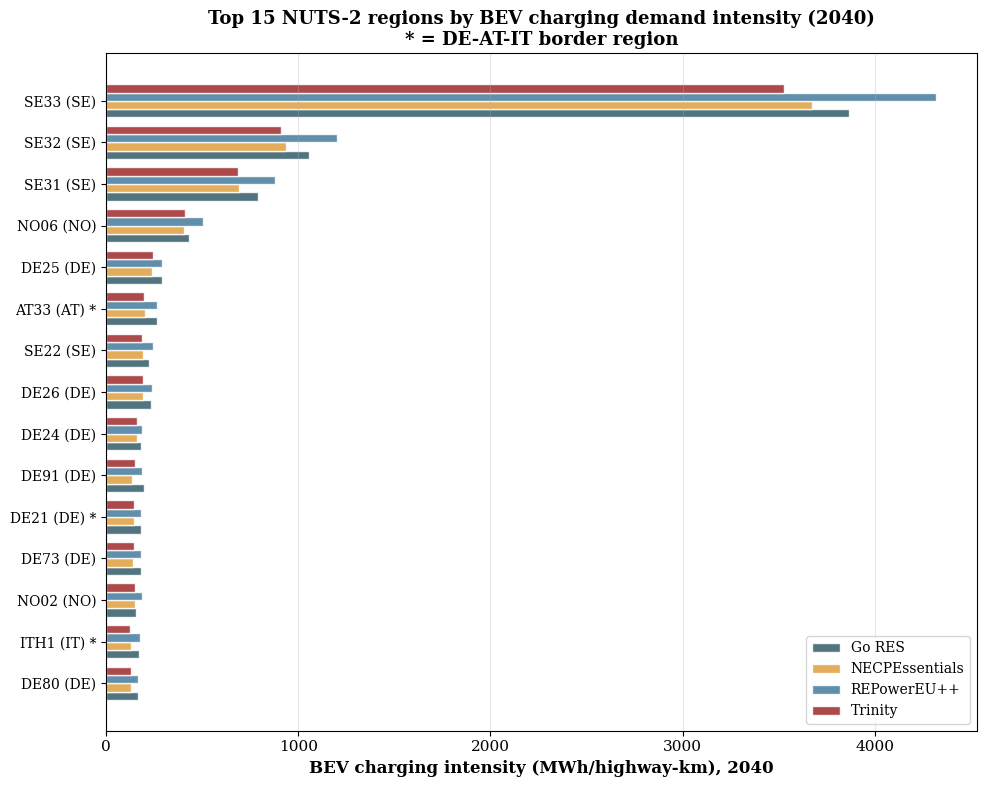

Saved: figures/charging_intensity_hwkm_top15_2040.pdf


In [199]:
# ============================================================
# Figure 3: Bar chart — Top 15 NUTS-2 regions by MWh/highway-km
# Grouped by scenario, for 2040
# ============================================================

PLOT_YEAR = 2040
df = intensity_dfs[PLOT_YEAR].copy()
df = df[df['highway_km'] > 0]  # exclude regions with no highway

scen_cols = [f'{s}_mwh_per_hwkm' for s in SCEN_NAMES]
df['avg_intensity'] = df[scen_cols].mean(axis=1)
top15 = df.nlargest(15, 'avg_intensity').copy()
top15 = top15.sort_values('avg_intensity', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
y_pos = np.arange(len(top15))
bar_height = 0.2

for si, scen_name in enumerate(SCEN_NAMES):
    col = f'{scen_name}_mwh_per_hwkm'
    ax.barh(y_pos + si * bar_height, top15[col].values,
            height=bar_height, label=scen_name,
            color=SCENARIO_COLORS[scen_name], alpha=0.85, edgecolor='white')

labels = []
for _, r in top15.iterrows():
    marker = ' *' if r['is_border'] else ''
    labels.append(f"{r['nuts2']} ({r['country']}){marker}")

ax.set_yticks(y_pos + 1.5 * bar_height)
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel(f'BEV charging intensity (MWh/highway-km), {PLOT_YEAR}',
              fontweight='bold', fontsize=12)
ax.legend(fontsize=10, loc='lower right')
ax.grid(axis='x', alpha=0.3)
ax.set_title(f'Top 15 NUTS-2 regions by BEV charging demand intensity ({PLOT_YEAR})\n'
             f'* = DE-AT-IT border region', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_top15_{PLOT_YEAR}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_top15_{PLOT_YEAR}.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: figures/charging_intensity_hwkm_top15_{PLOT_YEAR}.pdf')

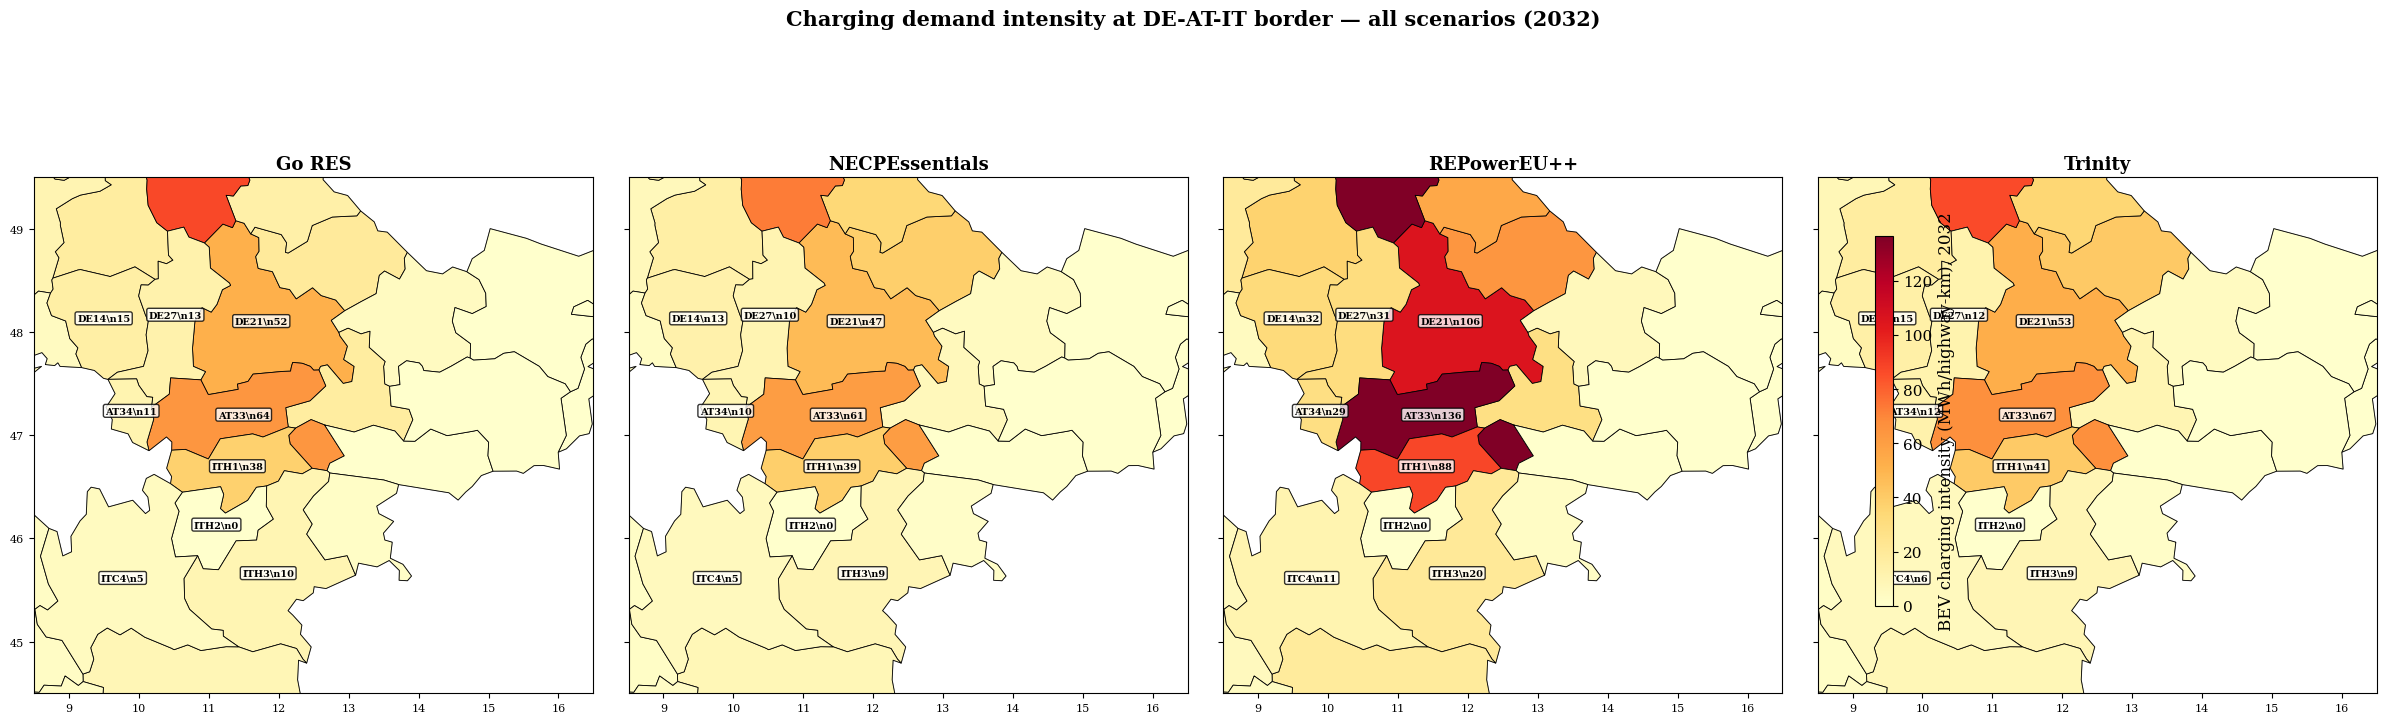

Saved: figures/charging_intensity_hwkm_border_zoom_2032.pdf


In [209]:
# ============================================================
# Figure 4: Border region zoom — MWh/highway-km for DE-AT-IT
# Choropleth zoomed to border region, 4 scenarios
# ============================================================

PLOT_YEAR = 2032
fig, axes = plt.subplots(1, 4, figsize=(24, 8))

XLIM = (8.5, 16.5)
YLIM = (44.5, 49.5)

border_area_gdf = corridor_with_hw[
    (corridor_with_hw.geometry.centroid.y >= YLIM[0] - 1) &
    (corridor_with_hw.geometry.centroid.y <= YLIM[1] + 1) &
    (corridor_with_hw.geometry.centroid.x >= XLIM[0] - 1) &
    (corridor_with_hw.geometry.centroid.x <= XLIM[1] + 1)
].copy()

vmax = 0
for scen_name in SCEN_NAMES:
    col = f'{scen_name}_mwh_per_hwkm'
    df = intensity_dfs[PLOT_YEAR]
    border_vals = df[(df['is_border']) & (df['highway_km'] > 0)][col]
    if len(border_vals) > 0:
        vmax = max(vmax, border_vals.max())

for si, scen_name in enumerate(SCEN_NAMES):
    ax = axes[si]
    df = intensity_dfs[PLOT_YEAR]
    col = f'{scen_name}_mwh_per_hwkm'
    
    plot_gdf = border_area_gdf.merge(
        df[['nuts2', col, 'highway_km']], left_on='NUTS_ID', right_on='nuts2', how='left'
    )
    plot_gdf[col] = plot_gdf[col].fillna(0)
    
    corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
    plot_gdf.plot(
        ax=ax, column=col, cmap='YlOrRd',
        edgecolor='black', linewidth=0.6,
        vmin=0, vmax=vmax, legend=False,
    )
    
    for idx, row in plot_gdf.iterrows():
        if row['NUTS_ID'] in SOUTHERN_BORDER_REGIONS:
            centroid = row.geometry.centroid
            hw = row.get('highway_km_y', row.get('highway_km', 0))
            val = row[col]
            ax.annotate(
                f"{row['NUTS_ID']}\\n{val:,.0f}",
                xy=(centroid.x, centroid.y), ha='center', va='center',
                fontsize=7, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8)
            )
    
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_title(scen_name, fontweight='bold', fontsize=13)
    if si > 0:
        ax.set_yticklabels([])
    ax.tick_params(labelsize=8)

sm = cm.ScalarMappable(cmap='YlOrRd', norm=Normalize(vmin=0, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), shrink=0.6, pad=0.02)
cbar.set_label(f'BEV charging intensity (MWh/highway-km), {PLOT_YEAR}', fontsize=12)

fig.suptitle(f'Charging demand intensity at DE-AT-IT border \u2014 all scenarios ({PLOT_YEAR})',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_border_zoom_{PLOT_YEAR}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'charging_intensity_hwkm_border_zoom_{PLOT_YEAR}.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: figures/charging_intensity_hwkm_border_zoom_{PLOT_YEAR}.pdf')

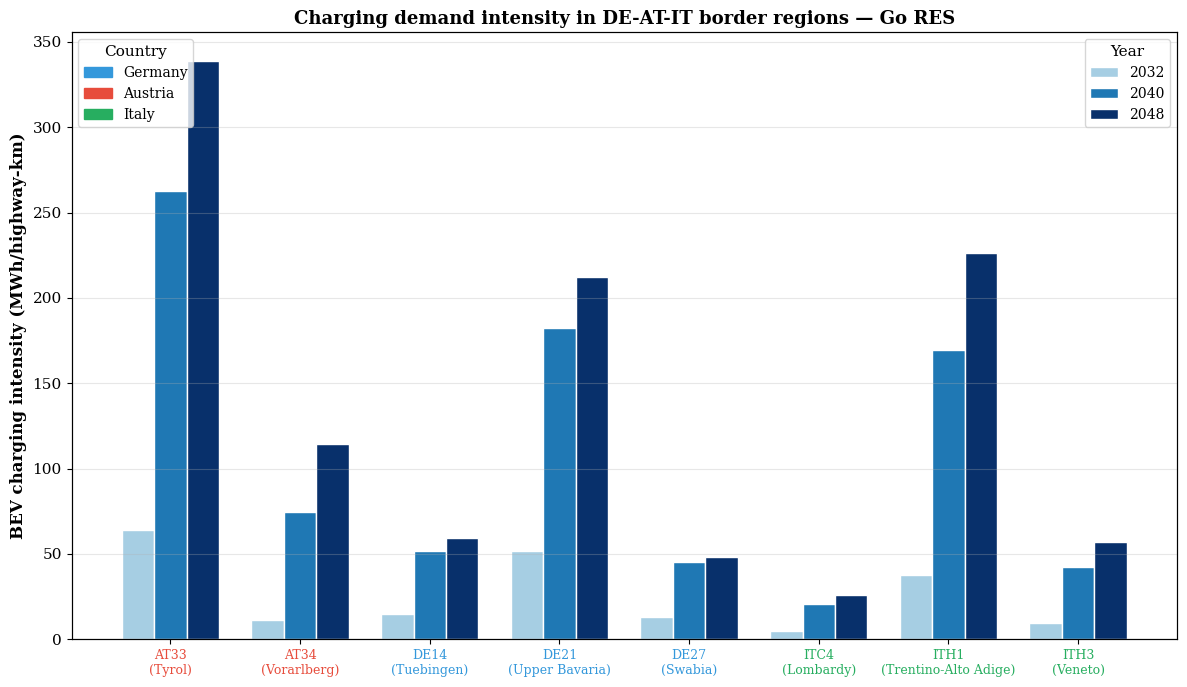

Saved: figures/charging_intensity_border_timeseries.pdf


In [201]:
# ============================================================
# Figure 5: Border regions — bar chart over time
# MWh/highway-km for each border NUTS-2, grouped by year
# ============================================================

scen_name = 'Go RES'  # Focus on Go RES

# Collect border region data across years
border_rows = []
for year in ANALYSIS_YEARS:
    df = intensity_dfs[year]
    border_df = df[(df['is_border']) & (df['highway_km'] > 0)].copy()
    for _, r in border_df.iterrows():
        border_rows.append({
            'nuts2': r['nuts2'],
            'country': r['country'],
            'year': year,
            'mwh_per_hwkm': r[f'{scen_name}_mwh_per_hwkm'],
            'total_gwh': r[f'{scen_name}_mwh'] / 1e3,
            'highway_km': r['highway_km'],
        })

border_time_df = pd.DataFrame(border_rows)

# Pivot for grouped bar chart
pivot = border_time_df.pivot(index='nuts2', columns='year', values='mwh_per_hwkm')
pivot = pivot.reindex(sorted(pivot.index))  # sort alphabetically

# Add country for coloring
country_map = dict(zip(border_time_df['nuts2'], border_time_df['country']))

fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(pivot))
width = 0.25
year_colors = {2032: '#a6cee3', 2040: '#1f78b4', 2048: '#08306b'}

for yi, year in enumerate(ANALYSIS_YEARS):
    vals = pivot[year].values
    bars = ax.bar(x + yi * width, vals, width, label=str(year),
                  color=year_colors[year], edgecolor='white')

# Color-coded labels by country
labels = []
label_colors = []
for nuts2 in pivot.index:
    c = country_map.get(nuts2, '??')
    name = REGION_NAMES.get(nuts2, nuts2)
    labels.append(f'{nuts2}\n({name})')
    label_colors.append(COUNTRY_COLORS_MAP.get(c, 'black'))

ax.set_xticks(x + width)
ax.set_xticklabels(labels, fontsize=9)
for tick, color in zip(ax.get_xticklabels(), label_colors):
    tick.set_color(color)

ax.set_ylabel('BEV charging intensity (MWh/highway-km)', fontweight='bold', fontsize=12)
ax.set_title(f'Charging demand intensity in DE-AT-IT border regions \u2014 {scen_name}',
             fontweight='bold', fontsize=13)
ax.legend(title='Year', fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Country legend
handles = [
    mpatches.Patch(color=COUNTRY_COLORS_MAP['DE'], label='Germany'),
    mpatches.Patch(color=COUNTRY_COLORS_MAP['AT'], label='Austria'),
    mpatches.Patch(color=COUNTRY_COLORS_MAP['IT'], label='Italy'),
]
ax2 = ax.twinx()
ax2.set_yticks([])
ax2.legend(handles=handles, loc='upper left', fontsize=10, title='Country')

plt.tight_layout()
plt.savefig(FIG_DIR / 'charging_intensity_border_timeseries.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'charging_intensity_border_timeseries.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/charging_intensity_border_timeseries.pdf')

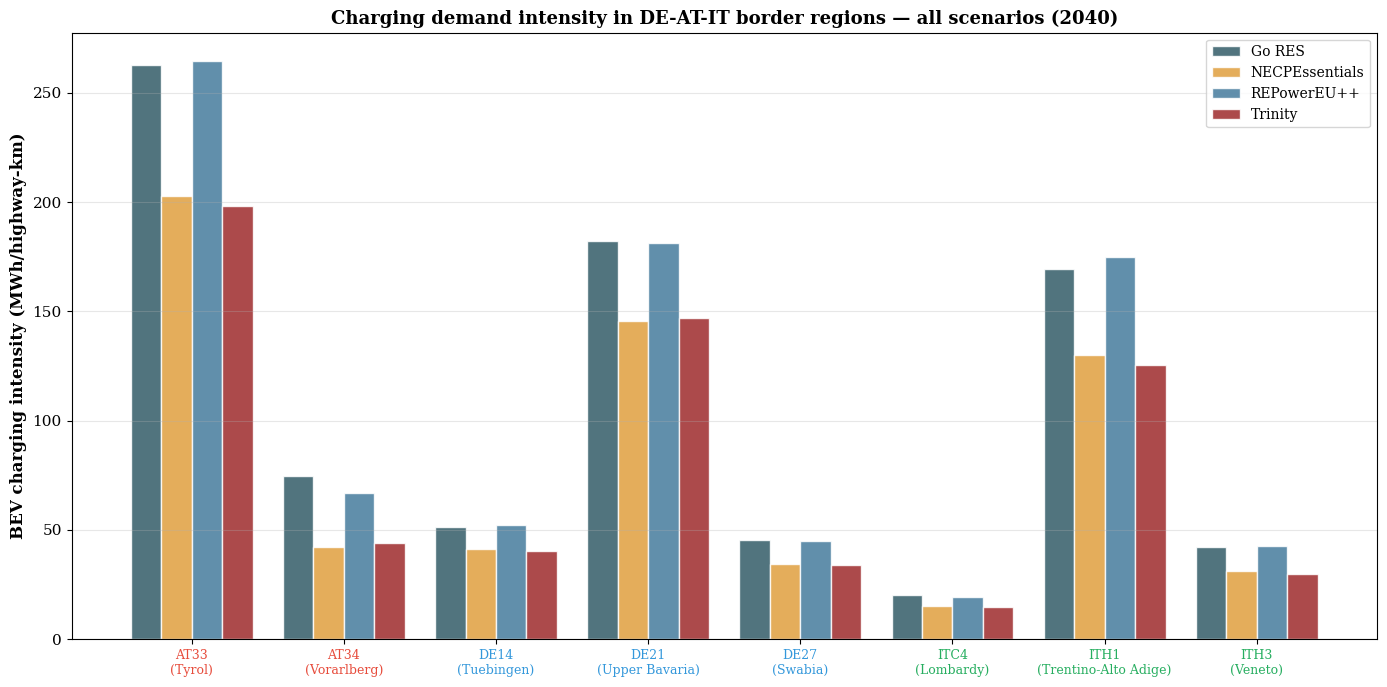

Saved: figures/charging_intensity_border_4scenarios_2040.pdf


In [202]:
# ============================================================
# Figure 6: Border region intensity \u2014 all 4 scenarios comparison
# ============================================================

PLOT_YEAR = 2040
df = intensity_dfs[PLOT_YEAR]
border_df = df[(df['is_border']) & (df['highway_km'] > 0)].copy().sort_values('nuts2')

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(border_df))
width = 0.2

for si, scen_name in enumerate(SCEN_NAMES):
    col = f'{scen_name}_mwh_per_hwkm'
    vals = border_df[col].values
    ax.bar(x + si * width, vals, width, label=scen_name,
           color=SCENARIO_COLORS[scen_name], alpha=0.85, edgecolor='white')

# Labels
labels = []
label_colors = []
for _, r in border_df.iterrows():
    name = REGION_NAMES.get(r['nuts2'], r['nuts2'])
    labels.append(f"{r['nuts2']}\n({name})")
    label_colors.append(COUNTRY_COLORS_MAP.get(r['country'], 'black'))

ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(labels, fontsize=9)
for tick, color in zip(ax.get_xticklabels(), label_colors):
    tick.set_color(color)

ax.set_ylabel('BEV charging intensity (MWh/highway-km)', fontweight='bold', fontsize=12)
ax.set_title(f'Charging demand intensity in DE-AT-IT border regions \u2014 '
             f'all scenarios ({PLOT_YEAR})', fontweight='bold', fontsize=13)
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / f'charging_intensity_border_4scenarios_{PLOT_YEAR}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'charging_intensity_border_4scenarios_{PLOT_YEAR}.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: figures/charging_intensity_border_4scenarios_{PLOT_YEAR}.pdf')

In [203]:
# ============================================================
# Summary statistics table
# ============================================================

print('=' * 90)
print('SUMMARY: BEV charging intensity by country (MWh/highway-km, 2040, Go RES)')
print('=' * 90)

df = intensity_dfs[2040]
for country in sorted(df['country'].unique()):
    cdf = df[df['country'] == country]
    valid = cdf[cdf['highway_km'] > 0]
    total_mwh = valid['Go RES_mwh'].sum()
    total_hwkm = valid['highway_km'].sum()
    avg = total_mwh / total_hwkm if total_hwkm > 0 else 0
    n_border = valid['is_border'].sum()
    border_str = f' ({n_border} border)' if n_border > 0 else ''
    print(f'  {country}: {len(valid)} regions{border_str}, '
          f'total={total_mwh/1e3:.2f} GWh, highway={total_hwkm:,.0f} km, '
          f'avg intensity={avg:,.0f} MWh/highway-km')

print(f'\n--- Border vs non-border comparison ---')
border = df[(df['is_border']) & (df['highway_km'] > 0)]
non_border = df[(~df['is_border']) & (df['highway_km'] > 0)]
b_avg = border['Go RES_mwh'].sum() / border['highway_km'].sum() if border['highway_km'].sum() > 0 else 0
nb_avg = non_border['Go RES_mwh'].sum() / non_border['highway_km'].sum() if non_border['highway_km'].sum() > 0 else 0
print(f'  Border regions:     avg {b_avg:,.0f} MWh/highway-km ({len(border)} regions)')
print(f'  Non-border regions: avg {nb_avg:,.0f} MWh/highway-km ({len(non_border)} regions)')
print(f'  Ratio: {b_avg/nb_avg:.1f}x' if nb_avg > 0 else '')

# Save intensity data as CSV
for year in ANALYSIS_YEARS:
    intensity_dfs[year].to_csv(FIG_DIR / f'charging_intensity_nuts2_{year}.csv', index=False)
print(f'\nSaved CSV files to figures/')

SUMMARY: BEV charging intensity by country (MWh/highway-km, 2040, Go RES)
  AT: 4 regions (2 border), total=67.90 GWh, highway=695 km, avg intensity=98 MWh/highway-km
  DE: 38 regions (3 border), total=1002.97 GWh, highway=13,210 km, avg intensity=76 MWh/highway-km
  DK: 5 regions, total=34.08 GWh, highway=1,357 km, avg intensity=25 MWh/highway-km
  FI: 1 regions, total=5.98 GWh, highway=145 km, avg intensity=41 MWh/highway-km
  IT: 18 regions (3 border), total=215.55 GWh, highway=6,827 km, avg intensity=32 MWh/highway-km
  NO: 5 regions, total=59.04 GWh, highway=636 km, avg intensity=93 MWh/highway-km
  SE: 8 regions, total=277.88 GWh, highway=2,194 km, avg intensity=127 MWh/highway-km

--- Border vs non-border comparison ---
  Border regions:     avg 88 MWh/highway-km (8 regions)
  Non-border regions: avg 63 MWh/highway-km (71 regions)
  Ratio: 1.4x

Saved CSV files to figures/


Loaded 6134 mandatory breaks

Top 15 NUTS-2 regions by break count:
 NUTS2  Country  Total  Short  Rest   HW-km  Brk/HW-km  Border
  DE21       DE    482    322   160     634       0.76       *
  DE80       DE    423    227   196     578       0.73        
  AT33       AT    396    220   176     189       2.10       *
  DE25       DE    352    228   124     268       1.32        
  SE22       SE    321    196   125     395       0.81        
  DE40       DE    290    152   138     807       0.36        
  ITH3       IT    288    192    96     701       0.41       *
  ITH1       IT    284    165   119     187       1.52       *
  ITH5       IT    236    147    89     677       0.35        
  ITH2       IT    217    121    96       0       0.00       *
  DEE0       DE    216    122    94     522       0.41        
  DE26       DE    210    135    75     305       0.69        
  SE23       SE    203    122    81     592       0.34        
  DE24       DE    146     79    67     262       

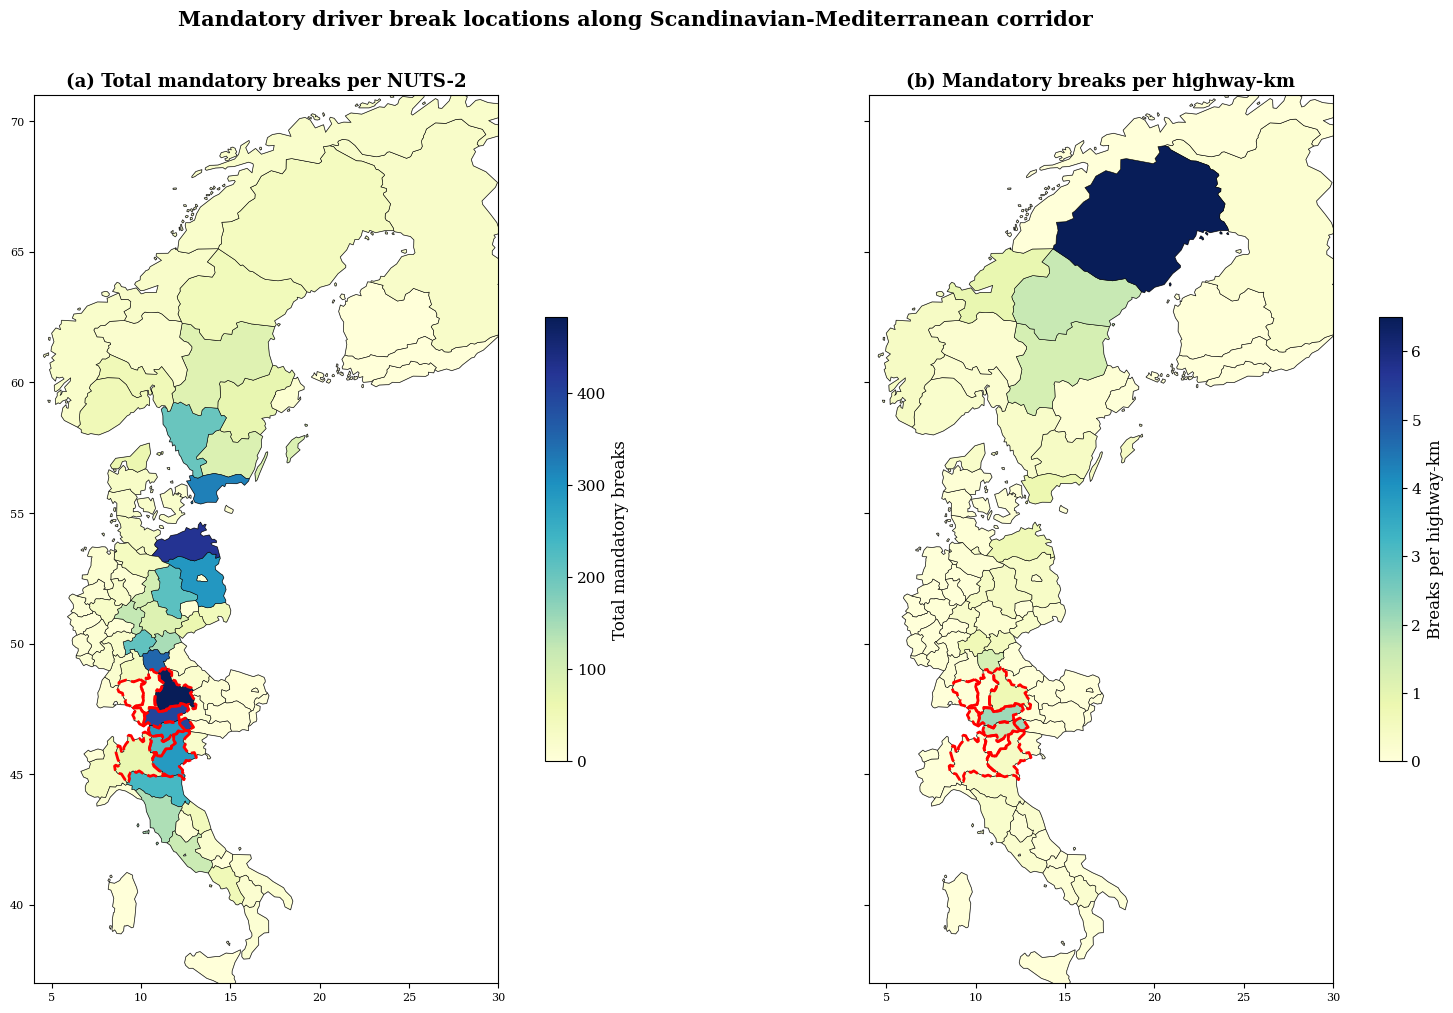

Saved: figures/mandatory_breaks_map.pdf


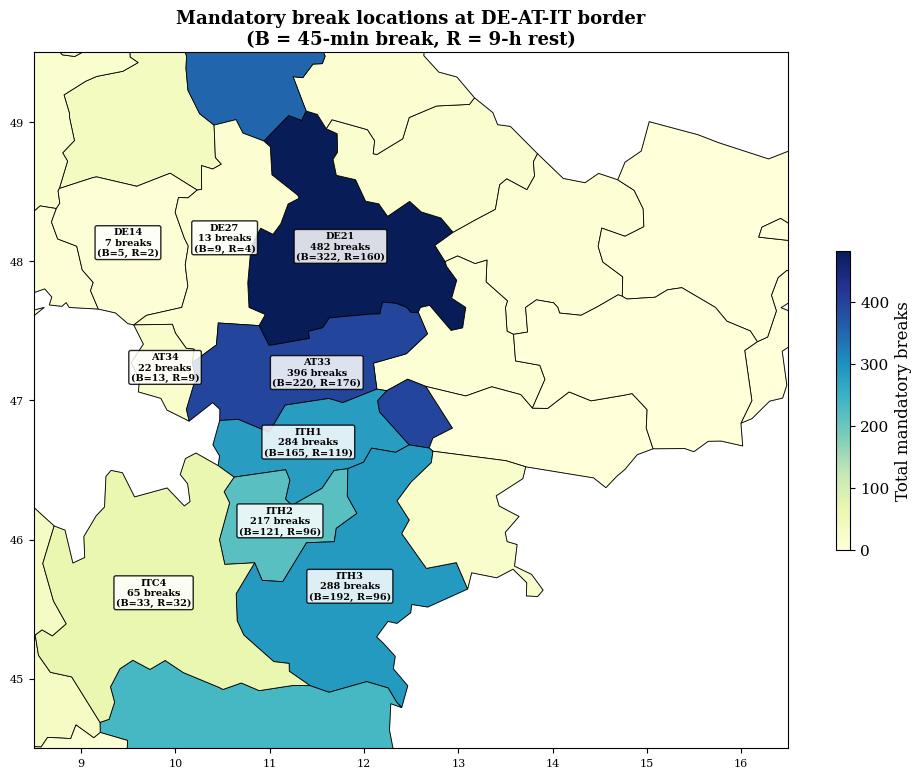

Saved: figures/mandatory_breaks_border_zoom.pdf

--- Break summary ---
Total breaks: 6134
  Short (B=45min): 3539
  Rest (R=9h): 2595
Regions with breaks: 81
Border region breaks: 1774 (28.9% of total)


In [204]:
# ============================================================
# Figure 7: Mandatory break locations — choropleth map
# Shows break density (breaks per highway-km) per NUTS-2 region
# Uses scenario_000 MandatoryBreaks.yaml (same paths across all scenarios)
# ============================================================

# Load mandatory breaks from scenario_000 (identical paths across scenarios)
breaks_yaml = load_yaml_file(INPUT_DIR / 'uncertainty_scenarios' / 'scenario_000' / 'MandatoryBreaks.yaml')
print(f'Loaded {len(breaks_yaml)} mandatory breaks')

# Count breaks per NUTS-2 region
breaks_per_nuts2 = defaultdict(int)
break_types_per_nuts2 = defaultdict(lambda: defaultdict(int))

for brk in breaks_yaml:
    geo_id = brk['latest_geo_id']
    nuts2 = geo_to_nuts2.get(geo_id, '')
    if nuts2:
        breaks_per_nuts2[nuts2] += 1
        btype = brk.get('break_type', 'unknown')
        break_types_per_nuts2[nuts2][btype] += 1

# Build break density DataFrame
break_rows = []
for nuts2 in sorted(breaks_per_nuts2.keys()):
    hw_km = highway_by_nuts2.get(nuts2, 0)
    area = area_by_nuts2.get(nuts2, 0)
    country = nuts2[:2]
    n_short = break_types_per_nuts2[nuts2].get('break', 0)
    n_rest = break_types_per_nuts2[nuts2].get('rest', 0)
    break_rows.append({
        'nuts2': nuts2,
        'country': country,
        'total_breaks': breaks_per_nuts2[nuts2],
        'short_breaks': n_short,
        'rest_breaks': n_rest,
        'highway_km': hw_km,
        'area_km2': area,
        'breaks_per_hwkm': breaks_per_nuts2[nuts2] / hw_km if hw_km > 0 else 0,
        'is_border': nuts2 in SOUTHERN_BORDER_REGIONS,
    })

break_df = pd.DataFrame(break_rows)

# Print top regions
print(f'\nTop 15 NUTS-2 regions by break count:')
print(f"{'NUTS2':>6} {'Country':>8} {'Total':>6} {'Short':>6} {'Rest':>5} {'HW-km':>7} {'Brk/HW-km':>10} {'Border':>7}")
for _, r in break_df.nlargest(15, 'total_breaks').iterrows():
    border = '*' if r['is_border'] else ''
    print(f"{r['nuts2']:>6} {r['country']:>8} {r['total_breaks']:6d} "
          f"{r['short_breaks']:6d} {r['rest_breaks']:5d} "
          f"{r['highway_km']:7.0f} {r['breaks_per_hwkm']:10.2f} {border:>7}")

# ---- Choropleth: Full corridor ----
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Panel 1: Total break count per NUTS-2
ax = axes[0]
plot_gdf = corridor_with_hw.merge(
    break_df[['nuts2', 'total_breaks']],
    left_on='NUTS_ID', right_on='nuts2', how='left'
)
plot_gdf['total_breaks'] = plot_gdf['total_breaks'].fillna(0)

corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
plot_gdf.plot(
    ax=ax, column='total_breaks', cmap='YlGnBu',
    edgecolor='black', linewidth=0.4,
    legend=True, legend_kwds={'label': 'Total mandatory breaks', 'shrink': 0.5},
)
border_gdf = plot_gdf[plot_gdf['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)]
border_gdf.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2, linestyle='--')

ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_title('(a) Total mandatory breaks per NUTS-2', fontweight='bold', fontsize=13)
ax.tick_params(labelsize=8)

# Panel 2: Breaks per highway-km
ax = axes[1]
plot_gdf2 = corridor_with_hw.merge(
    break_df[['nuts2', 'breaks_per_hwkm']],
    left_on='NUTS_ID', right_on='nuts2', how='left'
)
plot_gdf2['breaks_per_hwkm'] = plot_gdf2['breaks_per_hwkm'].fillna(0)

corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
plot_gdf2.plot(
    ax=ax, column='breaks_per_hwkm', cmap='YlGnBu',
    edgecolor='black', linewidth=0.4,
    legend=True, legend_kwds={'label': 'Breaks per highway-km', 'shrink': 0.5},
)
border_gdf2 = plot_gdf2[plot_gdf2['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)]
border_gdf2.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2, linestyle='--')

ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_title('(b) Mandatory breaks per highway-km', fontweight='bold', fontsize=13)
ax.tick_params(labelsize=8)
ax.set_yticklabels([])

fig.suptitle('Mandatory driver break locations along Scandinavian-Mediterranean corridor',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'mandatory_breaks_map.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'mandatory_breaks_map.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/mandatory_breaks_map.pdf')

# ---- Border zoom ----
fig, ax = plt.subplots(figsize=(10, 8))

XLIM = (8.5, 16.5)
YLIM = (44.5, 49.5)

border_area_gdf = corridor_with_hw[
    (corridor_with_hw.geometry.centroid.y >= YLIM[0] - 1) &
    (corridor_with_hw.geometry.centroid.y <= YLIM[1] + 1) &
    (corridor_with_hw.geometry.centroid.x >= XLIM[0] - 1) &
    (corridor_with_hw.geometry.centroid.x <= XLIM[1] + 1)
].copy()

plot_gdf3 = border_area_gdf.merge(
    break_df[['nuts2', 'total_breaks', 'short_breaks', 'rest_breaks', 'breaks_per_hwkm']],
    left_on='NUTS_ID', right_on='nuts2', how='left'
)
plot_gdf3['total_breaks'] = plot_gdf3['total_breaks'].fillna(0)

corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
plot_gdf3.plot(
    ax=ax, column='total_breaks', cmap='YlGnBu',
    edgecolor='black', linewidth=0.6,
    legend=True, legend_kwds={'label': 'Total mandatory breaks', 'shrink': 0.4},
)

# Annotate border regions
for idx, row in plot_gdf3.iterrows():
    if row['NUTS_ID'] in SOUTHERN_BORDER_REGIONS:
        centroid = row.geometry.centroid
        total = int(row.get('total_breaks', 0))
        short = int(row.get('short_breaks', 0))
        rest = int(row.get('rest_breaks', 0))
        name = REGION_NAMES.get(row['NUTS_ID'], row['NUTS_ID'])
        ax.annotate(
            f"{row['NUTS_ID']}\n{total} breaks\n(B={short}, R={rest})",
            xy=(centroid.x, centroid.y), ha='center', va='center',
            fontsize=7, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85)
        )

ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.set_title('Mandatory break locations at DE-AT-IT border\n(B = 45-min break, R = 9-h rest)',
             fontweight='bold', fontsize=13)
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'mandatory_breaks_border_zoom.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'mandatory_breaks_border_zoom.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/mandatory_breaks_border_zoom.pdf')

# Summary
print(f'\n--- Break summary ---')
print(f'Total breaks: {break_df["total_breaks"].sum()}')
print(f'  Short (B=45min): {break_df["short_breaks"].sum()}')
print(f'  Rest (R=9h): {break_df["rest_breaks"].sum()}')
print(f'Regions with breaks: {len(break_df)}')
border_breaks = break_df[break_df['is_border']]['total_breaks'].sum()
total_breaks = break_df['total_breaks'].sum()
print(f'Border region breaks: {border_breaks} ({border_breaks/total_breaks*100:.1f}% of total)')


Paths with freight in 2040: 2244
Total freight: 30191 kt
Breaks with missing path freight data: 0
Top 5 weighted regions:
  DE21: 7,517 kt-breaks (unweighted: 482)
  AT33: 6,862 kt-breaks (unweighted: 396)
  DE25: 4,374 kt-breaks (unweighted: 352)
  ITH1: 4,200 kt-breaks (unweighted: 284)
  DE26: 4,140 kt-breaks (unweighted: 210)


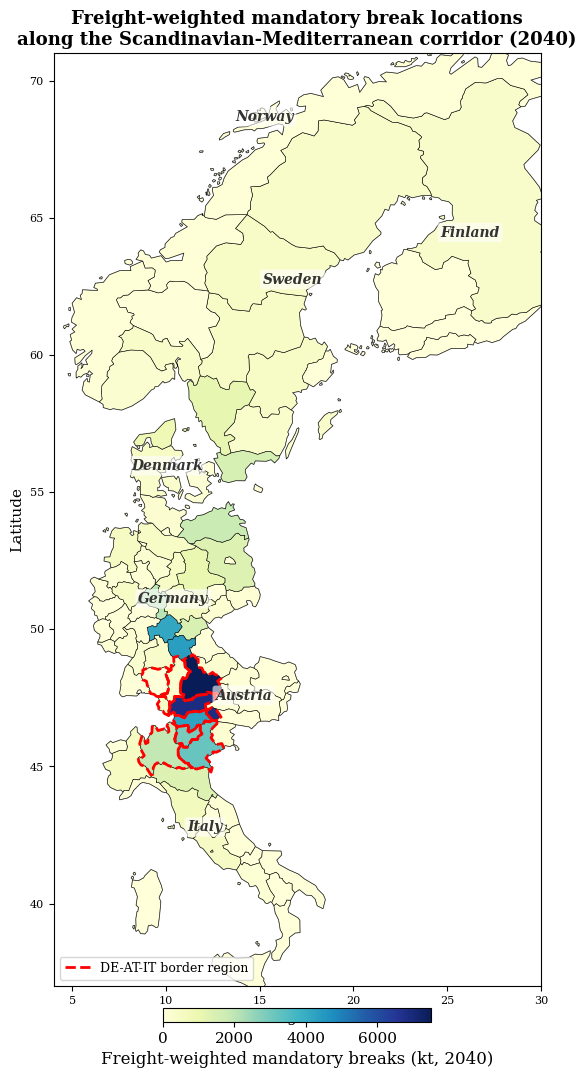

Saved: figures/mandatory_breaks_map_left_only.pdf


In [205]:
# ============================================================
# Figure 7b: Left panel only — tonnage-weighted mandatory breaks per NUTS-2
# Single-panel version for manuscript (Section 3 — Case study)
# Breaks weighted by freight volume (kt) on each path, year 2040
# ============================================================

# --- Step 1: compute total freight (kt) per path_id in reference year ---
WEIGHT_YEAR = 2040
go_res_f = data['Go RES']['f']

tonnes_per_path = defaultdict(float)  # path_id -> total kt (all techs, modes, gens)
for key, val_kt in go_res_f.items():
    year = key[0]
    if year != WEIGHT_YEAR:
        continue
    path_id = key[1][2]
    tonnes_per_path[path_id] += val_kt  # kt

print(f"Paths with freight in {WEIGHT_YEAR}: {len(tonnes_per_path)}")
print(f"Total freight: {sum(tonnes_per_path.values()):.0f} kt")

# --- Step 2: weight breaks by freight on their path ---
weighted_breaks_per_nuts2 = defaultdict(float)
unweighted_breaks_per_nuts2 = defaultdict(int)
missing_paths = 0

for brk in breaks_yaml:
    geo_id = brk['latest_geo_id']
    nuts2 = geo_to_nuts2.get(geo_id, '')
    pid = brk['path_id']
    if nuts2:
        weight = tonnes_per_path.get(pid, 0.0)
        weighted_breaks_per_nuts2[nuts2] += weight
        unweighted_breaks_per_nuts2[nuts2] += 1
        if pid not in tonnes_per_path:
            missing_paths += 1

print(f"Breaks with missing path freight data: {missing_paths}")
print(f"Top 5 weighted regions:")
for nuts2, wt in sorted(weighted_breaks_per_nuts2.items(), key=lambda x: -x[1])[:5]:
    uw = unweighted_breaks_per_nuts2[nuts2]
    print(f"  {nuts2}: {wt:,.0f} kt-breaks (unweighted: {uw})")

# --- Step 3: build weighted break DataFrame ---
weighted_break_rows = []
for nuts2 in sorted(weighted_breaks_per_nuts2.keys()):
    weighted_break_rows.append({
        'nuts2': nuts2,
        'weighted_breaks': weighted_breaks_per_nuts2[nuts2],
        'unweighted_breaks': unweighted_breaks_per_nuts2[nuts2],
    })
weighted_break_df = pd.DataFrame(weighted_break_rows)

# --- Step 4: plot ---
fig, ax = plt.subplots(figsize=(8, 12))

plot_gdf = corridor_with_hw.merge(
    weighted_break_df[['nuts2', 'weighted_breaks']],
    left_on='NUTS_ID', right_on='nuts2', how='left'
)
plot_gdf['weighted_breaks'] = plot_gdf['weighted_breaks'].fillna(0)

corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
plot_gdf.plot(
    ax=ax, column='weighted_breaks', cmap='YlGnBu',
    edgecolor='black', linewidth=0.4,
    legend=True, legend_kwds={'label': f'Freight-weighted mandatory breaks (kt, {WEIGHT_YEAR})',
                               'shrink': 0.35, 'orientation': 'horizontal', 'pad': 0.02},
)

# Border regions with legend handle
border_gdf = plot_gdf[plot_gdf['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)]
border_gdf.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2, linestyle='--')

# Country name labels at centroids
country_names = {'AT': 'Austria', 'DE': 'Germany', 'IT': 'Italy',
                 'DK': 'Denmark', 'SE': 'Sweden', 'NO': 'Norway', 'FI': 'Finland'}
for _, row in corridor_countries_gdf.iterrows():
    cc = row['CNTR_CODE']
    if cc in country_names:
        centroid = row.geometry.centroid
        ax.text(centroid.x, centroid.y, country_names[cc],
                ha='center', va='center', fontsize=10, fontweight='bold',
                color='#333', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6, edgecolor='none'))

# Legend for border region
from matplotlib.lines import Line2D
border_handle = Line2D([0], [0], color='red', linewidth=2, linestyle='--', label='DE-AT-IT border region')
ax.legend(handles=[border_handle], loc='lower left', fontsize=9, framealpha=0.8)

ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude', fontsize=11)
ax.set_title(f'Freight-weighted mandatory break locations\nalong the Scandinavian-Mediterranean corridor ({WEIGHT_YEAR})',
             fontweight='bold', fontsize=13)
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'mandatory_breaks_map_left_only.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'mandatory_breaks_map_left_only.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/mandatory_breaks_map_left_only.pdf')

Found 6 shapefiles:
  lines.shp  (0 KB)
  output_linestring.shp  (0 KB)
  roads_GL2017_CNC_E.shp  (619 KB)
  roads_sep_tent.shp  (619 KB)
  sep_roads.shp  (0 KB)
  united_mlstring.shp  (605 KB)

roads_GL2017_CNC_E: 285 features
CRS: EPSG:3857
Columns: ['ID', 'COUNTRY_CO', 'MEMBER_STA', 'DESCRIPTIO', 'CORE_NETWO', 'STAGE_OF_S', 'MEASURE_TY', 'CORRIDORS', 'TYPE', 'INTROADNUM', 'NATIONALRO', 'ORDER_ALL', 'GEO_LENGTH', 'OBJECT_MOD', 'EDIT_DATE', 'GIS_STATUS', 'SHAPE_Leng', 'geometry']

Sample rows:


,ID,COUNTRY_CO,MEMBER_STA,DESCRIPTIO,CORE_NETWO,STAGE_OF_S,MEASURE_TY,CORRIDORS,TYPE,INTROADNUM,NATIONALRO,ORDER_ALL,GEO_LENGTH,OBJECT_MOD,EDIT_DATE,GIS_STATUS,SHAPE_Leng,geometry
0,25458,DK,1,Seaby <--> Aalborg (J. E39/E45),1,Completed,New Construction,E,Motorways,E045,E45,2336,51540.0,ROADS,2023-09-05,Completed,95083.277131,"LINESTRING (1109707.88 7777174.01, 1109886.27 ..."
1,22400250,IT,1,Firenze Certosa <--> Monte San Savino (A1),1,Under construction/Ongoing,Upgrade,E,Motorways,E035,A1,1409,72358.0,ROADS,2023-09-05,To be upgraded,99901.236958,"LINESTRING (1309580.746 5366621.369, 1309114.0..."
2,23947,SE,1,Kronetorp <--> Helsingborg S,1,Completed,No Measure Type,E,Motorways,E006,E6,2391,49481.0,ROADS,2023-09-05,Completed,88031.072586,"LINESTRING (1458870.981 7487347.578, 1458835.7..."



Unique CORRIDORS (8):
CORRIDORS
E      244
BE      14
BDE     13
EI       6
AE       3
CE       2
DE       2
ACE      1

Unique COUNTRY_CO (8):
COUNTRY_CO
DE    71
DK    58
IT    54
SE    52
FI    25
MT    19
NO     4
AT     2

Unique TYPE (4):
TYPE
Motorways                              181
Rural road with separate directions     13
Rural two-lane road                     12
Urban roads                              8

Unique GIS_STATUS (3):
GIS_STATUS
Completed           208
To be upgraded       71
New Construction      6


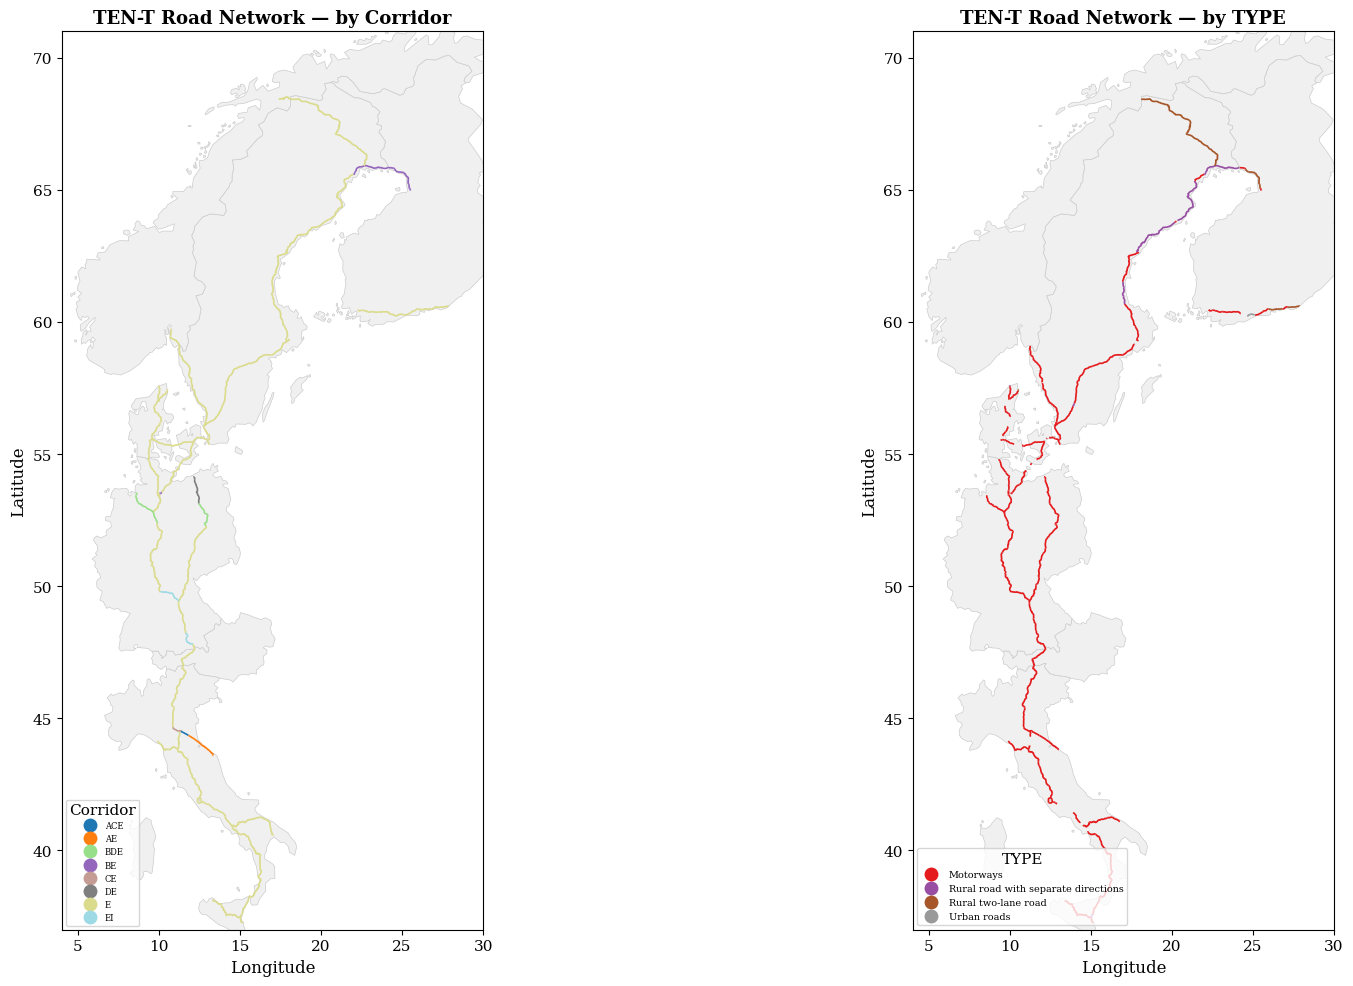

Saved: figures/tent_network_overview.png


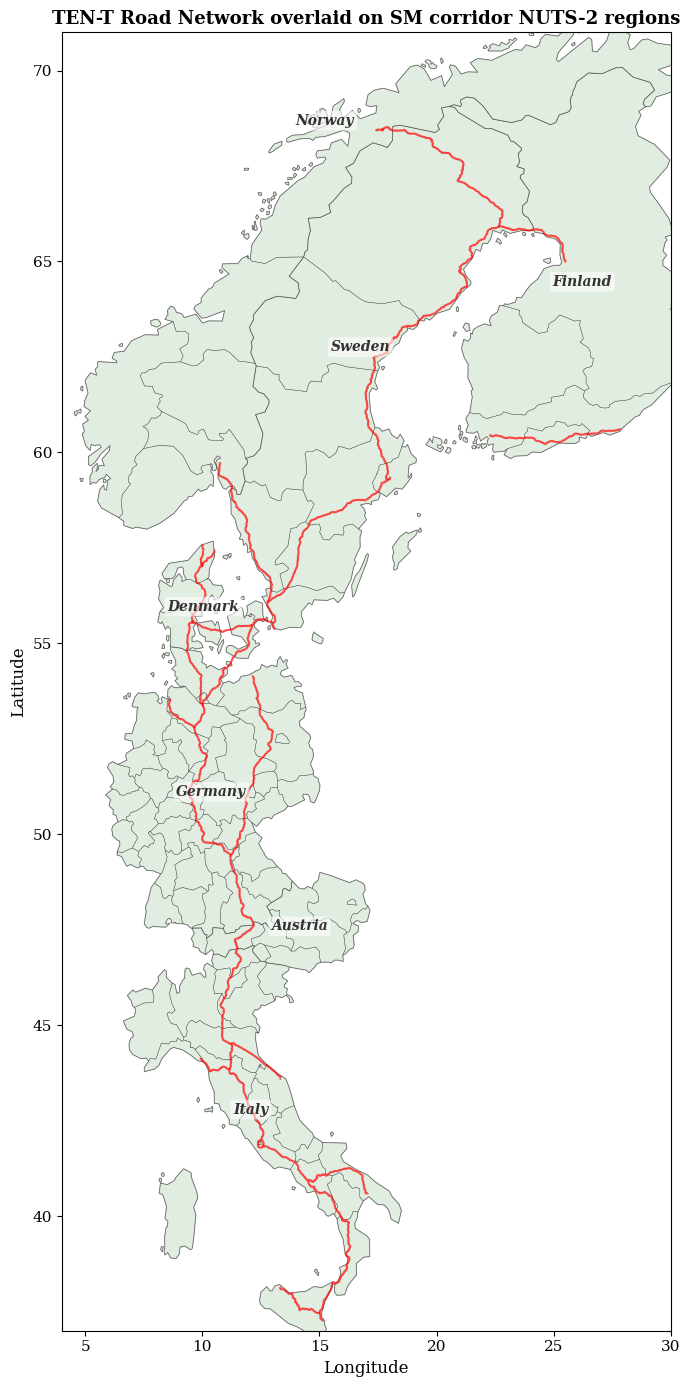

Saved: figures/tent_on_corridor.png


In [206]:
# ============================================================
# Explore TEN-T shapefiles — visual overview
# ============================================================
import geopandas as gpd
from pathlib import Path

tent_dir = Path(r'D:\AntoniaMariaG\ten-t')

# List all shapefiles
shp_files = list(tent_dir.glob('*.shp'))
print(f"Found {len(shp_files)} shapefiles:")
for f in shp_files:
    print(f"  {f.name}  ({f.stat().st_size / 1024:.0f} KB)")

# Load the main dataset (largest file)
tent_gdf = gpd.read_file(tent_dir / 'roads_GL2017_CNC_E.shp')
print(f"\nroads_GL2017_CNC_E: {len(tent_gdf)} features")
print(f"CRS: {tent_gdf.crs}")
print(f"Columns: {list(tent_gdf.columns)}")
print(f"\nSample rows:")
display(tent_gdf.head(3))

# Reproject to WGS84 for plotting alongside our corridor
tent_wgs84 = tent_gdf.to_crs(epsg=4326)

# Check unique values for key columns
for col in ['CORRIDORS', 'COUNTRY_CO', 'TYPE', 'GIS_STATUS']:
    if col in tent_wgs84.columns:
        print(f"\nUnique {col} ({tent_wgs84[col].nunique()}):")
        print(tent_wgs84[col].value_counts().head(10).to_string())

# --- Map 1: Full TEN-T network colored by corridor ---
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

ax = axes[0]
corridor_countries_gdf.plot(ax=ax, color='#f0f0f0', edgecolor='#ccc', linewidth=0.5)
tent_wgs84.plot(ax=ax, column='CORRIDORS', cmap='tab20', linewidth=1.2,
                legend=True, legend_kwds={'fontsize': 6, 'loc': 'lower left', 'title': 'Corridor'})
ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_title('TEN-T Road Network — by Corridor', fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# --- Map 2: colored by GIS_STATUS or TYPE ---
ax = axes[1]
color_col = 'TYPE' if 'TYPE' in tent_wgs84.columns else 'GIS_STATUS'
corridor_countries_gdf.plot(ax=ax, color='#f0f0f0', edgecolor='#ccc', linewidth=0.5)
tent_wgs84.plot(ax=ax, column=color_col, cmap='Set1', linewidth=1.2,
                legend=True, legend_kwds={'fontsize': 7, 'loc': 'lower left', 'title': color_col})
ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_title(f'TEN-T Road Network — by {color_col}', fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.tight_layout()
plt.savefig(FIG_DIR / 'tent_network_overview.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/tent_network_overview.png')

# --- Map 3: TEN-T overlaid on our corridor NUTS-2 regions ---
fig, ax = plt.subplots(figsize=(10, 14))
corridor_countries_gdf.plot(ax=ax, color='#f5f5f5', edgecolor='#999', linewidth=0.8)
corridor_with_hw.plot(ax=ax, color='#d4e8d4', edgecolor='black', linewidth=0.3, alpha=0.6)
tent_wgs84.plot(ax=ax, color='red', linewidth=1.5, alpha=0.7)

for _, row in corridor_countries_gdf.iterrows():
    cc = row['CNTR_CODE']
    name = {'AT': 'Austria', 'DE': 'Germany', 'IT': 'Italy',
            'DK': 'Denmark', 'SE': 'Sweden', 'NO': 'Norway', 'FI': 'Finland'}.get(cc, '')
    if name:
        c = row.geometry.centroid
        ax.text(c.x, c.y, name, ha='center', va='center', fontsize=10, fontweight='bold',
                color='#333', fontstyle='italic',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6, edgecolor='none'))

ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('TEN-T Road Network overlaid on SM corridor NUTS-2 regions', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'tent_on_corridor.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/tent_on_corridor.png')

In [207]:

import yaml
import pandas as pd
import numpy as np
from collections import Counter, defaultdict

# Load the files
breaks_file = r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\MandatoryBreaks.yaml'
geo_file = r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\GeographicElement.yaml'
path_file = r'C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\fixed_nuts_2\Path.yaml'

print("Loading data files...")

with open(breaks_file, 'r') as f:
    breaks_data = yaml.load(f, Loader=yaml.UnsafeLoader)

with open(geo_file, 'r') as f:
    geo_data = yaml.load(f, Loader=yaml.UnsafeLoader)

with open(path_file, 'r') as f:
    path_data = yaml.load(f, Loader=yaml.UnsafeLoader)

print(f"Loaded {len(breaks_data)} breaks")
print(f"Loaded {len(geo_data)} geographic elements")
print(f"Loaded {len(path_data)} paths")


Loading data files...
Loaded 6134 breaks
Loaded 81 geographic elements
Loaded 6055 paths


In [208]:

# Create geo_id to name mapping
geo_map = {}
for geo in geo_data:
    geo_map[geo['id']] = {
        'nuts_id': geo.get('nuts_id', 'N/A'),
        'name': geo.get('name', 'N/A'),
        'lat': geo.get('lat', None),
        'lon': geo.get('lon', None)
    }

# Q1: Count breaks per geo_id and show top 15
geo_break_counts = Counter()
for brk in breaks_data:
    geo_break_counts[brk['geo_id']] += 1

print("\n" + "="*80)
print("Q1: TOP 15 NODES BY BREAK COUNT")
print("="*80)
top_15 = geo_break_counts.most_common(15)
print(f"\n{'Rank':<5} {'Geo_ID':<8} {'Count':<8} {'NUTS-2':<12} {'Name':<40}")
print("-"*80)
for rank, (geo_id, count) in enumerate(top_15, 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts_id', 'N/A')
    name = geo_info.get('name', 'N/A')
    print(f"{rank:<5} {geo_id:<8} {count:<8} {nuts:<12} {name[:40]:<40}")

print(f"\nTotal breaks across all nodes: {sum(geo_break_counts.values())}")
print(f"Breaks at geo_id=8 (Munich): {geo_break_counts[8]} ({100*geo_break_counts[8]/sum(geo_break_counts.values()):.1f}%)")


KeyError: 'geo_id'

In [ ]:

# Check structure of breaks data
print("Sample break entry:")
if breaks_data:
    print(breaks_data[0])
    print("\nKeys:", breaks_data[0].keys() if isinstance(breaks_data[0], dict) else "Not a dict")


Sample break entry:
{'break_duration': 0.75, 'break_number': 1, 'break_type': 'break', 'cumulative_distance': 390.58285898892154, 'cumulative_driving_time': 4.882285737361519, 'id': 0, 'latest_geo_id': 58, 'latest_node_idx': 4, 'mode': 'road', 'num_drivers': 1, 'path_id': 0, 'path_length': 841.326697370376, 'time_with_breaks': 5.632285737361519, 'total_driving_time': 4.882285737361519}

Keys: dict_keys(['break_duration', 'break_number', 'break_type', 'cumulative_distance', 'cumulative_driving_time', 'id', 'latest_geo_id', 'latest_node_idx', 'mode', 'num_drivers', 'path_id', 'path_length', 'time_with_breaks', 'total_driving_time'])


In [ ]:

# The field is 'latest_geo_id' not 'geo_id'
geo_break_counts = Counter()
for brk in breaks_data:
    geo_break_counts[brk['latest_geo_id']] += 1

print("\n" + "="*80)
print("Q1: TOP 15 NODES BY BREAK COUNT")
print("="*80)
top_15 = geo_break_counts.most_common(15)
print(f"\n{'Rank':<5} {'Geo_ID':<8} {'Count':<8} {'NUTS-2':<12} {'Name':<40}")
print("-"*80)
for rank, (geo_id, count) in enumerate(top_15, 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts_id', 'N/A')
    name = geo_info.get('name', 'N/A')
    print(f"{rank:<5} {geo_id:<8} {count:<8} {nuts:<12} {name[:40]:<40}")

total_breaks = sum(geo_break_counts.values())
munich_breaks = geo_break_counts[8]
print(f"\nTotal breaks across all nodes: {total_breaks}")
print(f"Breaks at geo_id=8 (Munich): {munich_breaks} ({100*munich_breaks/total_breaks:.1f}%)")



Q1: TOP 15 NODES BY BREAK COUNT

Rank  Geo_ID   Count    NUTS-2       Name                                    
--------------------------------------------------------------------------------
1     8        482      N/A          nuts2_DE21                              
2     22       423      N/A          nuts2_DE80                              
3     2        396      N/A          nuts2_AT33                              
4     12       352      N/A          nuts2_DE25                              
5     76       321      N/A          nuts2_SE22                              
6     16       290      N/A          nuts2_DE40                              
7     60       288      N/A          nuts2_ITH3                              
8     58       284      N/A          nuts2_ITH1                              
9     62       236      N/A          nuts2_ITH5                              
10    59       217      N/A          nuts2_ITH2                              
11    39       216      N/A

In [ ]:

# Fix: geo_data doesn't have 'name' field, the nuts_id IS the name
# Re-create geo_map
geo_map = {}
for geo in geo_data:
    geo_map[geo['id']] = {
        'nuts_id': geo.get('nuts_id', 'N/A'),
        'lat': geo.get('lat', None),
        'lon': geo.get('lon', None)
    }

# Map NUTS2 codes to region names
nuts2_names = {
    'DE21': 'Upper Bavaria (Munich)',
    'DE80': 'Mecklenburg-Vorpommern',
    'AT33': 'Tyrol',
    'DE25': 'Middle Franconia',
    'SE22': 'South Sweden',
    'DE40': 'Brandenburg',
    'ITH3': 'Veneto',
    'ITH1': 'Bolzano/South Tyrol',
    'ITH5': 'Emilia-Romagna',
    'ITH2': 'Trento',
    'DEE0': 'Saxony-Anhalt',
    'DE26': 'Lower Franconia',
    'SE23': 'West Sweden',
    'DE24': 'Upper Franconia',
    'ITI1': 'Tuscany'
}

print("\n" + "="*90)
print("Q1: TOP 15 NODES BY BREAK COUNT")
print("="*90)
top_15 = geo_break_counts.most_common(15)
print(f"\n{'Rank':<5} {'Geo_ID':<8} {'Count':<8} {'NUTS-2':<12} {'Region Name':<50}")
print("-"*90)
for rank, (geo_id, count) in enumerate(top_15, 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts_id', 'N/A')
    # Extract just the nuts code part
    nuts_code = nuts.split('_')[-1] if '_' in nuts else nuts
    region_name = nuts2_names.get(nuts_code, nuts)
    print(f"{rank:<5} {geo_id:<8} {count:<8} {nuts_code:<12} {region_name:<50}")

print(f"\nTotal breaks across all nodes: {total_breaks}")
print(f"Breaks at geo_id=8 (Munich): {munich_breaks} ({100*munich_breaks/total_breaks:.1f}%)")



Q1: TOP 15 NODES BY BREAK COUNT

Rank  Geo_ID   Count    NUTS-2       Region Name                                       
------------------------------------------------------------------------------------------
1     8        482      N/A          N/A                                               
2     22       423      N/A          N/A                                               
3     2        396      N/A          N/A                                               
4     12       352      N/A          N/A                                               
5     76       321      N/A          N/A                                               
6     16       290      N/A          N/A                                               
7     60       288      N/A          N/A                                               
8     58       284      N/A          N/A                                               
9     62       236      N/A          N/A                                           

In [ ]:

# Check the geo_data structure more carefully
print("Sample geo element:")
print(geo_data[8])  # Check Munich specifically


Sample geo element:
{'id': 8, 'name': 'nuts2_DE21', 'type': 'node', 'nuts2_region': 'DE21', 'country': 'DE', 'coordinate_lat': 48.13899565217391, 'coordinate_long': 11.722013043478258, 'from': 999999, 'to': 999999, 'length': 0.0, 'carbon_price': [30.0, 47.0, 64.0, 81.0, 98.0, 115.0, 132.0, 149.0, 166.0, 183.0, 200.0, 230.0, 260.0, 290.0, 320.0, 350.0, 380.0, 410.0, 440.0, 470.0, 500.0, 550.0, 600.0, 650.0, 700.0, 750.0, 800.0, 850.0, 900.0, 950.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0, 1000.0]}


In [ ]:

# Good! The field is 'name' and 'nuts2_region'. Re-create properly
geo_map = {}
for geo in geo_data:
    geo_map[geo['id']] = {
        'name': geo.get('name', 'N/A'),
        'nuts2_region': geo.get('nuts2_region', 'N/A'),
        'country': geo.get('country', 'N/A'),
        'lat': geo.get('coordinate_lat', None),
        'lon': geo.get('coordinate_long', None)
    }

print("\n" + "="*100)
print("Q1: TOP 15 NODES BY BREAK COUNT")
print("="*100)
top_15 = geo_break_counts.most_common(15)
print(f"\n{'Rank':<5} {'Geo_ID':<8} {'Count':<8} {'NUTS-2':<10} {'Country':<8} {'Region Name':<40}")
print("-"*100)
for rank, (geo_id, count) in enumerate(top_15, 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts2_region', 'N/A')
    country = geo_info.get('country', 'N/A')
    region_name = nuts2_names.get(nuts, nuts)
    print(f"{rank:<5} {geo_id:<8} {count:<8} {nuts:<10} {country:<8} {region_name:<40}")

print(f"\nTotal breaks: {total_breaks}")
print(f"Breaks at geo_id=8 (Munich/DE21): {munich_breaks} ({100*munich_breaks/total_breaks:.1f}%)")



Q1: TOP 15 NODES BY BREAK COUNT

Rank  Geo_ID   Count    NUTS-2     Country  Region Name                             
----------------------------------------------------------------------------------------------------
1     8        482      DE21       DE       Upper Bavaria (Munich)                  
2     22       423      DE80       DE       Mecklenburg-Vorpommern                  
3     2        396      AT33       AT       Tyrol                                   
4     12       352      DE25       DE       Middle Franconia                        
5     76       321      SE22       SE       South Sweden                            
6     16       290      DE40       DE       Brandenburg                             
7     60       288      ITH3       IT       Veneto                                  
8     58       284      ITH1       IT       Bolzano/South Tyrol                     
9     62       236      ITH5       IT       Emilia-Romagna                          
10    59       

In [ ]:

# Q2: For breaks at geo_id=8, analyze break_type, break_number, and cumulative_driving_time
munich_breaks_data = [brk for brk in breaks_data if brk['latest_geo_id'] == 8]

print("\n" + "="*80)
print("Q2: ANALYSIS OF BREAKS AT GEO_ID=8 (MUNICH/DE21)")
print("="*80)

# Break type distribution
break_types = Counter([brk['break_type'] for brk in munich_breaks_data])
print(f"\nBreak Type Distribution (n={len(munich_breaks_data)}):")
for break_type, count in break_types.most_common():
    print(f"  {break_type:<10}: {count:>4} ({100*count/len(munich_breaks_data):>5.1f}%)")

# Break number distribution
break_numbers = Counter([brk['break_number'] for brk in munich_breaks_data])
print(f"\nBreak Number Distribution:")
for break_num in sorted(break_numbers.keys()):
    count = break_numbers[break_num]
    print(f"  Break #{break_num:<2}: {count:>4} ({100*count/len(munich_breaks_data):>5.1f}%)")

# Cumulative driving time distribution
driving_times = [brk['cumulative_driving_time'] for brk in munich_breaks_data]
print(f"\nCumulative Driving Time at Break (hours):")
print(f"  Min:    {min(driving_times):.2f} h")
print(f"  25th%:  {np.percentile(driving_times, 25):.2f} h")
print(f"  Median: {np.percentile(driving_times, 50):.2f} h")
print(f"  75th%:  {np.percentile(driving_times, 75):.2f} h")
print(f"  Max:    {max(driving_times):.2f} h")
print(f"  Mean:   {np.mean(driving_times):.2f} h")

# Histogram of driving times
bins = [0, 3, 4, 5, 6, 9, 20]
hist, _ = np.histogram(driving_times, bins=bins)
print(f"\nDriving Time Histogram:")
for i in range(len(bins)-1):
    print(f"  {bins[i]:.1f}-{bins[i+1]:.1f}h: {hist[i]:>4} ({100*hist[i]/len(driving_times):>5.1f}%)")



Q2: ANALYSIS OF BREAKS AT GEO_ID=8 (MUNICH/DE21)

Break Type Distribution (n=482):
  break     :  322 ( 66.8%)
  rest      :  160 ( 33.2%)

Break Number Distribution:
  Break #1 :  260 ( 53.9%)
  Break #2 :  139 ( 28.8%)
  Break #3 :   61 ( 12.7%)
  Break #4 :   21 (  4.4%)
  Break #5 :    1 (  0.2%)

Cumulative Driving Time at Break (hours):
  Min:    4.51 h
  25th%:  5.63 h
  Median: 7.05 h
  75th%:  10.42 h
  Max:    22.65 h
  Mean:   8.81 h

Driving Time Histogram:
  0.0-3.0h:    0 (  0.0%)
  3.0-4.0h:    0 (  0.0%)
  4.0-5.0h:   57 ( 11.8%)
  5.0-6.0h:  134 ( 27.8%)
  6.0-9.0h:   69 ( 14.3%)
  9.0-20.0h:  212 ( 44.0%)


In [ ]:

# Q3: Analyze origin nodes for paths with breaks at Munich
# Get path IDs that have breaks at Munich
munich_path_ids = set([brk['path_id'] for brk in munich_breaks_data])

print("\n" + "="*80)
print("Q3: ORIGIN ANALYSIS FOR PATHS WITH BREAKS AT MUNICH")
print("="*80)
print(f"\nNumber of unique paths with breaks at Munich: {len(munich_path_ids)}")

# Extract origin node (first node in sequence) for each path
origins_for_munich_paths = []
for path in path_data:
    if path['id'] in munich_path_ids:
        # Get the first node in the sequence
        if path['sequence'] and len(path['sequence']) > 0:
            origin_node = path['sequence'][0]
            origins_for_munich_paths.append(origin_node)

# Count origins
origin_counts = Counter(origins_for_munich_paths)

print(f"\nTop 15 Origin Nodes for Paths Breaking at Munich:")
print(f"{'Rank':<5} {'Node_ID':<8} {'Count':<8} {'NUTS-2':<10} {'Country':<8} {'Region':<35}")
print("-"*80)
for rank, (node_id, count) in enumerate(origin_counts.most_common(15), 1):
    geo_info = geo_map.get(node_id, {})
    nuts = geo_info.get('nuts2_region', 'N/A')
    country = geo_info.get('country', 'N/A')
    region_name = nuts2_names.get(nuts, nuts)
    print(f"{rank:<5} {node_id:<8} {count:<8} {nuts:<10} {country:<8} {region_name:<35}")

# Check latitudes of top origins to see if ~4.5h driving distance pattern
print(f"\nOrigin Latitudes vs Munich (lat={geo_map[8]['lat']:.2f}):")
for rank, (node_id, count) in enumerate(origin_counts.most_common(10), 1):
    geo_info = geo_map.get(node_id, {})
    lat = geo_info.get('lat')
    if lat:
        lat_diff = abs(lat - geo_map[8]['lat'])
        print(f"  Node {node_id} (NUTS {geo_info.get('nuts2_region', 'N/A')}): lat={lat:.2f}, Δlat={lat_diff:.2f}°")



Q3: ORIGIN ANALYSIS FOR PATHS WITH BREAKS AT MUNICH

Number of unique paths with breaks at Munich: 482

Top 15 Origin Nodes for Paths Breaking at Munich:
Rank  Node_ID  Count    NUTS-2     Country  Region                             
--------------------------------------------------------------------------------
1     26       37       DE94       DE       DE94                               
2     27       30       DEA1       DE       DEA1                               
3     8        29       DE21       DE       Upper Bavaria (Munich)             
4     30       26       DEA4       DE       DEA4                               
5     9        22       DE22       DE       DE22                               
6     17       22       DE50       DE       DE50                               
7     24       22       DE92       DE       DE92                               
8     25       22       DE93       DE       DE93                               
9     15       21       DE30       DE       

In [ ]:

# Q4: How many paths pass through node 8 (Munich)?
paths_through_munich = 0
paths_with_munich_as_origin = 0
paths_with_munich_as_destination = 0

for path in path_data:
    sequence = path.get('sequence', [])
    if 8 in sequence:
        paths_through_munich += 1
        if sequence and sequence[0] == 8:
            paths_with_munich_as_origin += 1
        if sequence and sequence[-1] == 8:
            paths_with_munich_as_destination += 1

print("\n" + "="*80)
print("Q4: PATHS PASSING THROUGH NODE 8 (MUNICH)")
print("="*80)
print(f"\nTotal paths in Path.yaml: {len(path_data)}")
print(f"Paths passing through Munich (node 8): {paths_through_munich} ({100*paths_through_munich/len(path_data):.1f}%)")
print(f"  - Munich as origin: {paths_with_munich_as_origin}")
print(f"  - Munich as destination: {paths_with_munich_as_destination}")
print(f"  - Munich as intermediate: {paths_through_munich - paths_with_munich_as_origin - paths_with_munich_as_destination}")

# Double-check: paths with breaks at Munich vs paths passing through Munich
print(f"\nPaths with mandatory breaks at Munich: {len(munich_path_ids)}")
print(f"Paths passing through Munich: {paths_through_munich}")
print(f"Percentage of through-paths with breaks: {100*len(munich_path_ids)/paths_through_munich:.1f}%")



Q4: PATHS PASSING THROUGH NODE 8 (MUNICH)

Total paths in Path.yaml: 6055
Paths passing through Munich (node 8): 2026 (33.5%)
  - Munich as origin: 74
  - Munich as destination: 74
  - Munich as intermediate: 1878

Paths with mandatory breaks at Munich: 482
Paths passing through Munich: 2026
Percentage of through-paths with breaks: 23.8%


In [ ]:

# Additional insights: Check if the 4-5h driving pattern holds
# For 1st breaks at Munich, check the cumulative driving time
first_breaks_munich = [brk for brk in munich_breaks_data if brk['break_number'] == 1]

print("\n" + "="*80)
print("ADDITIONAL ANALYSIS: 1ST BREAKS AT MUNICH")
print("="*80)
print(f"\nTotal 1st breaks at Munich: {len(first_breaks_munich)} (out of {len(munich_breaks_data)} total)")

driving_times_first = [brk['cumulative_driving_time'] for brk in first_breaks_munich]
print(f"\nCumulative Driving Time for 1st Breaks at Munich:")
print(f"  Min:    {min(driving_times_first):.2f} h")
print(f"  25th%:  {np.percentile(driving_times_first, 25):.2f} h")
print(f"  Median: {np.percentile(driving_times_first, 50):.2f} h")
print(f"  75th%:  {np.percentile(driving_times_first, 75):.2f} h")
print(f"  Max:    {max(driving_times_first):.2f} h")
print(f"  Mean:   {np.mean(driving_times_first):.2f} h")

# Check 4.5h regulation
within_4_5h = sum(1 for t in driving_times_first if 4.0 <= t <= 5.0)
within_regulation = sum(1 for t in driving_times_first if t <= 4.5)
print(f"\n1st breaks at Munich occurring:")
print(f"  - Between 4.0-5.0h: {within_4_5h} ({100*within_4_5h/len(driving_times_first):.1f}%)")
print(f"  - At or before 4.5h regulation: {within_regulation} ({100*within_regulation/len(driving_times_first):.1f}%)")
print(f"  - After 4.5h: {len(driving_times_first) - within_regulation} ({100*(len(driving_times_first) - within_regulation)/len(driving_times_first):.1f}%)")

# Summary comparison with other top nodes
print("\n" + "="*80)
print("COMPARISON: TOP 5 NODES BY BREAK COUNT")
print("="*80)
print(f"{'Node':<6} {'NUTS-2':<8} {'Region':<25} {'Breaks':<8} {'1st Brk':<8} {'Pass-thru':<10} {'% w/ Brk':<8}")
print("-"*80)

for rank, (geo_id, count) in enumerate(geo_break_counts.most_common(5), 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts2_region', 'N/A')
    region_name = nuts2_names.get(nuts, nuts)[:24]
    
    # Count 1st breaks
    first_brk_count = sum(1 for brk in breaks_data if brk['latest_geo_id'] == geo_id and brk['break_number'] == 1)
    
    # Count paths through this node
    paths_thru = sum(1 for path in path_data if geo_id in path.get('sesquence', []))
    
    # Percentage with break
    pct_with_break = 100 * count / paths_thru if paths_thru > 0 else 0
    
    print(f"{geo_id:<6} {nuts:<8} {region_name:<25} {count:<8} {first_brk_count:<8} {paths_thru:<10} {pct_with_break:<7.1f}%")



ADDITIONAL ANALYSIS: 1ST BREAKS AT MUNICH

Total 1st breaks at Munich: 260 (out of 482 total)

Cumulative Driving Time for 1st Breaks at Munich:
  Min:    4.51 h
  25th%:  5.08 h
  Median: 5.66 h
  75th%:  6.01 h
  Max:    8.28 h
  Mean:   5.69 h

1st breaks at Munich occurring:
  - Between 4.0-5.0h: 57 (21.9%)
  - At or before 4.5h regulation: 0 (0.0%)
  - After 4.5h: 260 (100.0%)

COMPARISON: TOP 5 NODES BY BREAK COUNT
Node   NUTS-2   Region                    Breaks   1st Brk  Pass-thru  % w/ Brk
--------------------------------------------------------------------------------
8      DE21     Upper Bavaria (Munich)    482      260      0          0.0    %
22     DE80     Mecklenburg-Vorpommern    423      178      0          0.0    %
2      AT33     Tyrol                     396      184      0          0.0    %
12     DE25     Middle Franconia          352      169      0          0.0    %
76     SE22     South Sweden              321      128      0          0.0    %


In [ ]:

# Additional insights: Check if the 4-5h driving pattern holds
# For 1st breaks at Munich, check the cumulative driving time
first_breaks_munich = [brk for brk in munich_breaks_data if brk['break_number'] == 1]

print("\n" + "="*80)
print("ADDITIONAL ANALYSIS: 1ST BREAKS AT MUNICH")
print("="*80)
print(f"\nTotal 1st breaks at Munich: {len(first_breaks_munich)} (out of {len(munich_breaks_data)} total)")

driving_times_first = [brk['cumulative_driving_time'] for brk in first_breaks_munich]
print(f"\nCumulative Driving Time for 1st Breaks at Munich:")
print(f"  Min:    {min(driving_times_first):.2f} h")
print(f"  Median: {np.percentile(driving_times_first, 50):.2f} h")
print(f"  Mean:   {np.mean(driving_times_first):.2f} h")

# Check 4.5h regulation
within_4_5h = sum(1 for t in driving_times_first if 4.0 <= t <= 5.0)
within_regulation = sum(1 for t in driving_times_first if t <= 4.5)
print(f"\n1st breaks at Munich occurring:")
print(f"  - Between 4.0-5.0h: {within_4_5h} ({100*within_4_5h/len(driving_times_first):.1f}%)")
print(f"  - At or before 4.5h: {within_regulation} ({100*within_regulation/len(driving_times_first):.1f}%)")



ADDITIONAL ANALYSIS: 1ST BREAKS AT MUNICH

Total 1st breaks at Munich: 260 (out of 482 total)

Cumulative Driving Time for 1st Breaks at Munich:
  Min:    4.51 h
  Median: 5.66 h
  Mean:   5.69 h

1st breaks at Munich occurring:
  - Between 4.0-5.0h: 57 (21.9%)
  - At or before 4.5h: 0 (0.0%)


In [ ]:

# Compare top nodes
print("\n" + "="*85)
print("COMPARISON: TOP 5 NODES BY BREAK COUNT")
print("="*85)
print(f"{'Node':<6} {'NUTS-2':<8} {'Region':<25} {'Total':<7} {'1st':<6} {'Pass-thru':<10} {'% w/Brk':<8}")
print("-"*85)

for rank, (geo_id, count) in enumerate(geo_break_counts.most_common(5), 1):
    geo_info = geo_map.get(geo_id, {})
    nuts = geo_info.get('nuts2_region', 'N/A')
    region_name = nuts2_names.get(nuts, nuts)[:24]
    
    # Count 1st breaks
    first_brk_count = sum(1 for brk in breaks_data if brk['latest_geo_id'] == geo_id and brk['break_number'] == 1)
    
    # Count paths through this node
    paths_thru = sum(1 for path in path_data if geo_id in path.get('sequence', []))
    
    # Percentage with break
    pct_with_break = 100 * count / paths_thru if paths_thru > 0 else 0
    
    print(f"{geo_id:<6} {nuts:<8} {region_name:<25} {count:<7} {first_brk_count:<6} {paths_thru:<10} {pct_with_break:<7.1f}%")

print("\nKey: '% w/Brk' = percentage of paths through node that have a break there")



COMPARISON: TOP 5 NODES BY BREAK COUNT
Node   NUTS-2   Region                    Total   1st    Pass-thru  % w/Brk 
-------------------------------------------------------------------------------------
8      DE21     Upper Bavaria (Munich)    482     260    2026       23.8   %
22     DE80     Mecklenburg-Vorpommern    423     178    1749       24.2   %
2      AT33     Tyrol                     396     184    1937       20.4   %
12     DE25     Middle Franconia          352     169    1924       18.3   %
76     SE22     South Sweden              321     128    1479       21.7   %

Key: '% w/Brk' = percentage of paths through node that have a break there
